# Initial EDA — Manufacturing Measurements

Understand the CSV, apply the agreed cleaning rules, and compare measurements within consistent contexts.

**Start here:** The saved local run uses the included synthetic CSV. Change `CSV_PATH` to your production export and choose **Restart Kernel → Run All** to analyze that file.

**Rules applied throughout Parts I and II:** Remove extra exact source copies (keep the first); fill empty or whitespace-only unit labels with `Standard`; drop every row with missing or whitespace-only size; calculate deviation as `actual - nominal`. Changing nominal/tolerance values are legitimate specification differences and remain separate. No physical-unit conversion or specification pass/fail calculation is performed.

The source CSV and `df_raw` remain unchanged for traceability. Section 2 shows the original input. Section 3 creates the cleaned `df`, which supplies every analysis and comparison. Explicit source-audit and before/after tables retain excluded rows only to explain cleaning; they are not the analysis dataset.

Part I follows eight EDA steps. Part II audits cleaning, reviews unusual measurements, and performs the first vendor comparison. Read `To-Do.md` for completed work and remaining steps.


## 1. Objective and setup

**Purpose:** Select the CSV. The notebook automatically discovers and summarizes all feature/part/unit combinations. No feature or part filter is required.

`MAX_PLOT_GROUPS` limits optional per-group charts. `PLOT_GROUP_IDS` can select groups from the current Section 4 inventory; leaving it empty plots the largest complete groups first. Set `PLOT_COMBINATIONS=False` to skip those charts. None of these settings limit the tables.

If packages are missing, run `%pip install pandas numpy matplotlib seaborn` in a separate cell once. This notebook expects pandas 2 or later.

**Question to answer:** What does one row represent—one measurement, one inspection, or a repeated inspection? Record your answer in Section 8.


In [1]:
# Purpose: Set the file path and optional chart limits. All combinations are summarized.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CSV_PATH = Path("example_manufacturing_measurements.csv")
DATE_FORMAT = "%m/%d/%Y %H:%M"  # Screenshot format: month/day/year hour:minute.

pd.set_option("display.max_columns", 25)
sns.set_theme(style="whitegrid")
print("File:", CSV_PATH.resolve())
if CSV_PATH.name == "example_manufacturing_measurements.csv":
    print("SYNTHETIC EXAMPLE — these are not production measurements.")

# These settings limit only the per-group charts in Sections 4 and 6, not the tables.
PLOT_COMBINATIONS = True
MAX_PLOT_GROUPS = 3
PLOT_GROUP_IDS = []  # Optional: e.g. ["G001", "G003"] from the current Section 4 table.
TABLE_PREVIEW_ROWS = 20  # Full tables are retained and exported, even when the preview is shorter.
EXPORT_TABLES = True
SUMMARY_FOLDER = Path("initial_eda_summaries")

if not isinstance(MAX_PLOT_GROUPS, int) or MAX_PLOT_GROUPS < 0:
    raise ValueError("MAX_PLOT_GROUPS must be a nonnegative integer.")
if not isinstance(TABLE_PREVIEW_ROWS, int) or TABLE_PREVIEW_ROWS < 1:
    raise ValueError("TABLE_PREVIEW_ROWS must be a positive integer.")


File:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\example_manufacturing_measurements.csv

SYNTHETIC EXAMPLE — these are not production measurements.

## 2. Load and inspect the data

**Purpose:** See the size, columns, and first few records. All source columns initially load as text to preserve identifiers such as `000123`. Known measurement fields will be converted in the next section.

**Read the output:** The named `source_record` index is a one-based imported-record number. It remains useful after sorting; it is not necessarily a physical CSV line number.

The sample uses the screenshot's 20 column names and order. `type` and `is_pass_fail` are blank in the sample, as in the visible rows. `unit="Standard"` is preserved as a source label; this notebook does not infer inches or millimeters from it.


In [2]:
# Purpose: Load a source copy and a separate working copy without changing the CSV.
df_raw = pd.read_csv(CSV_PATH, dtype="string", keep_default_na=False, na_values=[""])
df_raw.index = pd.RangeIndex(1, len(df_raw) + 1, name="source_record")
df = df_raw.copy(deep=True)

expected_columns = [
    "feature_name", "actual", "nominal", "upper_tolerance", "lower_tolerance", "type",
    "deviation", "is_pass_fail", "feature_type", "unit", "part_number", "material_family",
    "size", "serial_no", "date", "work_order", "po_number", "vendor_id", "vendor_name", "commodity",
]
print("Expected columns absent:", [c for c in expected_columns if c not in df] or "None")
print("Additional columns:", [c for c in df if c not in expected_columns] or "None")

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("loaded_type"))


Expected columns absent:

None

Additional columns:

None

Rows: 162 | Columns: 20

Columns:

['feature_name', 'actual', 'nominal', 'upper_tolerance', 'lower_tolerance', 'type', 'deviation', 'is_pass_fail', 'feature_type', 'unit', 'part_number', 'material_family', 'size', 'serial_no', 'date', 'work_order', 'po_number', 'vendor_id', 'vendor_name', 'commodity']

,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,material_family,size,serial_no,date,work_order,po_number,vendor_id,vendor_name,commodity
source_record,,,,,,,,,,,,,,,,,,,,
1,_090_1,0.0199135,0.02,0.003,0.003,<NA>,-0.0000865,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000000,1/1/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
2,_090_1,<NA>,0.02,0.003,0.003,<NA>,-0.0001037,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000001,1/4/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
3,_090_1,check source,0.02,0.003,0.003,<NA>,-0.0000668,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000002,1/7/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
4,_090_1,0.0204212,0.02,0.003,0.003,<NA>,0.0004212,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000003,invalid date,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
5,_090_1,0.0199234,0.02,0.003,0.003,<NA>,-0.0000766,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000004,1/13/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS


,loaded_type
feature_name,string
actual,string
nominal,string
upper_tolerance,string
lower_tolerance,string
type,string
deviation,string
is_pass_fail,string
feature_type,string
unit,string


## 3. Basic data-quality checks and approved cleaning

**Purpose:** Prepare one cleaned dataset for every subsequent analysis.

1. Identify exact copies across every original CSV column, before trimming, unit filling, numeric conversion, or deviation recalculation. Keep the first occurrence. Repeated vendor IDs, part numbers, or measurement keys alone do not cause removal.
2. Trim surrounding whitespace and parse measurements and dates. Invalid values become missing and are counted. Preserve the original unit and supplied deviation for traceability.
3. Fill missing unit labels with `Standard`, with `unit_assumed_standard=True`. Existing nonempty labels remain unchanged apart from whitespace trimming. No conversion to inches or millimeters is implied.
4. Remove rows with missing size. Removal counts assign a row to the duplicate step first, then to the missing-size step, avoiding double-counting rows affected by both rules.
5. Use `deviation = actual - nominal` everywhere. Keep other missing measurements as missing; relevant comparisons exclude unusable values.

**Optional empty fields:** Exclude `is_pass_fail` and `type` from analysis only when entirely missing in the cleaned rows. Preserve them in the source and audit copies. Retain any populated field and always keep `feature_type`; missing pass/fail is unknown, not a pass.

**Read the output:** `cleaning_summary` reconciles original and retained counts. `cleaning_audit` contains one row per source record with the removal reason, unit assumption, and inclusion flag. The missing-value profile describes cleaned data. Raw duplicate evidence is labeled separately. Legitimate differences in nominal and tolerances remain separate throughout the notebook.


In [3]:
# Purpose: Apply the approved rules once; all later analysis uses this cleaned df.
exact_extra = df_raw.duplicated(keep="first")
exact_members = df_raw.duplicated(keep=False)
df = df_raw.copy(deep=True)
for column in df.columns:
    df[column] = df[column].str.strip().replace("", pd.NA)
for column in ["unit", "size"]:
    if column not in df:
        df[column] = pd.Series(pd.NA, index=df.index, dtype="string")

df["source_unit"] = df_raw.get("unit", pd.Series(pd.NA, index=df.index, dtype="string"))
df["source_deviation"] = df_raw.get("deviation", pd.Series(pd.NA, index=df.index, dtype="string"))
df["unit_assumed_standard"] = df.unit.isna()
df["unit"] = df.unit.fillna("Standard")
missing_size = df["size"].isna()

conversion_rows = []
for column in [c for c in ["actual", "nominal", "deviation", "upper_tolerance", "lower_tolerance"] if c in df]:
    original = df[column]
    converted = pd.to_numeric(original, errors="coerce").astype(float)
    invalid = original.notna() & (converted.isna() | ~np.isfinite(converted))
    conversion_rows.append({"column": column, "missing_before": int(original.isna().sum()),
                            "invalid_values": int(invalid.sum())})
    df[column] = converted.replace([np.inf, -np.inf], np.nan)
for column in ["actual", "nominal"]:
    if column not in df:
        df[column] = np.nan
with np.errstate(over="ignore", invalid="ignore"):
    df["deviation"] = (df.actual - df.nominal).replace([np.inf, -np.inf], np.nan)
if "date" in df:
    original_date = df["date"].copy()
    df["date"] = pd.to_datetime(original_date, errors="coerce", format=DATE_FORMAT)
    conversion_rows.append({"column": "date", "missing_before": int(original_date.isna().sum()),
                            "invalid_values": int((original_date.notna() & df.date.isna()).sum())})
print("Parsing audit of original rows; supplied deviation is audited but replaced by actual - nominal:")
display(pd.DataFrame(conversion_rows, columns=["column", "missing_before", "invalid_values"]))

cleaning_audit = pd.DataFrame({
    "extra_exact_copy": exact_extra, "missing_size": missing_size,
    "unit_assumed_standard": df.unit_assumed_standard,
}, index=df_raw.index)
cleaning_audit["included_in_analysis"] = ~exact_extra & ~missing_size
cleaning_audit["cleaning_status"] = np.select(
    [exact_extra, missing_size], ["removed: extra exact copy", "removed: missing size"], default="retained")
# Retain the full prepared input for explicitly labeled audits, never for regular analysis.
df_preclean = df.copy(deep=True)
df = df.loc[cleaning_audit.included_in_analysis].copy()
# Omit these optional fields only when they contain no values in cleaned data.
empty_columns = [column for column in ["is_pass_fail", "type"]
                 if column in df and df[column].isna().all()]
df = df.drop(columns=empty_columns)
print("Excluded entirely empty analysis columns:", empty_columns or "None")
cleaning_summary = pd.DataFrame({"step": [
    "Original rows", "Extra exact copies removed", "Rows after duplicate removal",
    "Additional rows removed for missing size", "Final cleaned rows",
    "Unit labels filled among final cleaned rows"], "records": [
    len(df_raw), int(exact_extra.sum()), int((~exact_extra).sum()),
    int((~exact_extra & missing_size).sum()), len(df), int(df.unit_assumed_standard.sum())]})
display(cleaning_summary)
print(f"Original rows missing size (including overlap with duplicates): {missing_size.sum():,}")
print(f"Original empty units assigned Standard (including rows later excluded): {df_preclean.unit_assumed_standard.sum():,}")
print("Full record decisions: cleaning_audit. Retained source-record numbers are not reset.")
display(cleaning_audit.head(TABLE_PREVIEW_ROWS))
assert len(df_raw) == int(exact_extra.sum()) + int((~exact_extra & missing_size).sum()) + len(df)
assert df.unit.notna().all() and df["size"].notna().all()
assert not df_raw.loc[df.index].duplicated().any()


Parsing audit of original rows; supplied deviation is audited but replaced by actual - nominal:

,column,missing_before,invalid_values
0,actual,1,1
1,nominal,0,0
2,deviation,0,0
3,upper_tolerance,0,0
4,lower_tolerance,0,0
5,date,0,1


Excluded entirely empty analysis columns:

['is_pass_fail', 'type']

,step,records
0,Original rows,162
1,Extra exact copies removed,2
2,Rows after duplicate removal,160
3,Additional rows removed for missing size,0
4,Final cleaned rows,160
5,Unit labels filled among final cleaned rows,0


Original rows missing size (including overlap with duplicates): 0

Original empty units assigned Standard (including rows later excluded): 0

Full record decisions: cleaning_audit. Retained source-record numbers are not reset.

,extra_exact_copy,missing_size,unit_assumed_standard,included_in_analysis,cleaning_status
source_record,,,,,
1,False,False,False,True,retained
2,False,False,False,True,retained
3,False,False,False,True,retained
4,False,False,False,True,retained
5,False,False,False,True,retained
6,False,False,False,True,retained
7,False,False,False,True,retained
8,False,False,False,True,retained
9,False,False,False,True,retained


Missingness and examples below use 160 cleaned rows.

,type,missing_count,missing_percent,unique_values,examples
actual,float64,2,1.2,158,"[0.0199135, 0.0204212, 0.0199234]"
deviation,float64,2,1.2,158,"[-8.649999999999977e-05, 0.0004212000000000000..."
date,datetime64[us],1,0.6,40,"[2026-01-01 14:27:00, 2026-01-04 14:27:00, 202..."
feature_name,string,0,0.0,2,"[_090_1, Key 040 .010 Profile Total_5]"
upper_tolerance,float64,0,0.0,2,"[0.003, 0.01]"
nominal,float64,0,0.0,2,"[0.02, 0.0]"
feature_type,string,0,0.0,2,"[Inner Diameter, Profile]"
unit,string,0,0.0,1,[Standard]
part_number,string,0,0.0,2,"[4A1534, 4A1206]"
lower_tolerance,float64,0,0.0,2,"[0.003, 0.0]"


Examples show up to three distinct values, not every value.

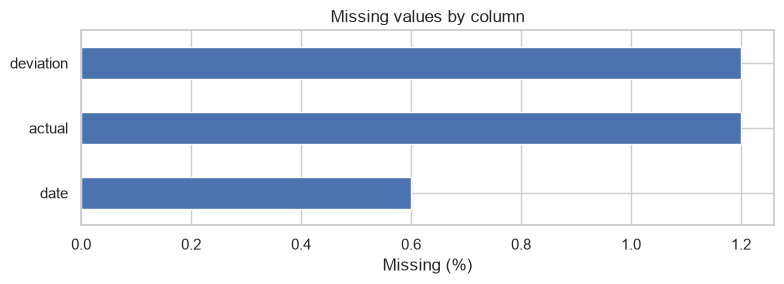

In [4]:
# Purpose: Profile the cleaned analysis fields; original-value audit columns remain available separately.
profile_data = df.drop(columns=["source_unit", "source_deviation", "unit_assumed_standard"])
print(f"Missingness and examples below use {len(df):,} cleaned rows.")
profile = pd.DataFrame({
    "type": profile_data.dtypes.astype(str),
    "missing_count": profile_data.isna().sum(),
    "missing_percent": profile_data.isna().mean().mul(100).round(1),
    "unique_values": profile_data.nunique(dropna=True),
    "examples": [profile_data[c].dropna().astype(str).unique()[:3].tolist() for c in profile_data],
}).sort_values("missing_percent", ascending=False)
display(profile)
print("Examples show up to three distinct values, not every value.")

missing = profile.loc[profile.missing_count > 0, "missing_percent"].sort_values()
if not missing.empty:
    missing.plot.barh(figsize=(8, max(3, len(missing) * 0.35)))
    plt.xlabel("Missing (%)"); plt.title("Missing values by column")
    plt.tight_layout(); plt.show()


In [5]:
# Purpose: Audit removed source copies, then inspect remaining repeated measurement keys.
exact_extra = df_raw.duplicated(keep="first")
exact_members = df_raw.duplicated(keep=False)
print("Source exact copies removed from analysis:", int(exact_extra.sum()))
print("Extra exact source copies remaining in cleaned data:", int(df_raw.loc[df.index].duplicated().sum()))
print("Original matching-record evidence (not analysis rows):")
display(df_raw.loc[exact_members].head(12))

measurement_key = ["serial_no", "part_number", "feature_name", "date"]
if set(measurement_key).issubset(df.columns):
    measurement_key += [c for c in ["vendor_id", "work_order"] if c in df]
    complete_key = df[measurement_key].notna().all(axis=1)
    repeated = complete_key & df.duplicated(measurement_key, keep=False)
    print("Rows in repeated complete-key groups:", int(repeated.sum()))
    print("Rows with incomplete candidate keys:", int((~complete_key).sum()))
    review_columns = measurement_key + [c for c in ["actual"] if c in df]
    display(df.loc[repeated, review_columns].sort_values(measurement_key).head(12))

for column in [c for c in ["lower_tolerance", "upper_tolerance"] if c in df]:
    print(f"Negative values in {column}: {int(df[column].lt(0).sum())} — confirm source conventions.")


Source exact copies removed from analysis:

2

Extra exact source copies remaining in cleaned data:

0

Original matching-record evidence (not analysis rows):

,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,material_family,size,serial_no,date,work_order,po_number,vendor_id,vendor_name,commodity
source_record,,,,,,,,,,,,,,,,,,,,
13,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS
59,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS
161,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS
162,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS


... (3 outputs left out)

1

,serial_no,part_number,feature_name,date,vendor_id,work_order,actual
source_record,,,,,,,


Negative values in lower_tolerance: 0 — confirm source conventions.

Negative values in upper_tolerance: 0 — confirm source conventions.

## 4. Numeric exploration

**Purpose:** Find every combination in the cleaned data and summarize measurements within consistent contexts. Removed copies and missing-size rows are excluded. Filled Standard labels participate in grouping. Legitimate nominal/tolerance differences remain separate without rounding or pooling.

| Table | A row represents | What to look for |
|---|---|---|
| Combination inventory | One feature name + part number + unit | Record counts, usable/missing measurements, vendors, dates, and changing specifications |
| Group statistics | Above, plus feature type, material, size, nominal, upper tolerance, lower tolerance | Mean, median, standard deviation, minimum, maximum, and comparison status |

Vendor is not part of the measurement-group definition: vendors are compared **within** each group. Serial numbers, dates, work orders, and purchase orders remain traceability fields. They do not split every measurement into its own group.

Missing grouping fields remain visible in the inventory and group table. Measurement statistics and vendor comparisons are skipped for incomplete contexts, negative tolerance allowances, or groups with no usable actual measurements. A complete context does not prove engineering validity or establish a vendor effect.

**Read the output:** `specification_variants` counts distinct nominal/tolerance combinations, including incomplete ones. `specifications_vary=True` means one exploration group contains more than one such combination. `comparison_groups` also reflects material, size, and feature-type differences. The preview shows up to `TABLE_PREVIEW_ROWS` rows; Section 8 saves the full tables.


In [6]:
# Purpose: Discover all exploration groups and comparable contexts without dropping missing keys.
EXPLORATION_KEYS = ["feature_name", "part_number", "unit"]
SPEC_KEYS = ["nominal", "upper_tolerance", "lower_tolerance"]
COMPARISON_KEYS = EXPLORATION_KEYS + ["feature_type", "material_family", "size"] + SPEC_KEYS

group_data = df_preclean.copy()
# Missing columns get placeholders only in this analysis copy, so their absence stays visible.
for column in COMPARISON_KEYS + ["actual", "vendor_id", "date"]:
    if column not in group_data:
        group_data[column] = pd.NaT if column == "date" else np.nan if column in SPEC_KEYS + ["actual"] else pd.NA
if not pd.api.types.is_datetime64_any_dtype(group_data.date):
    print("Group date coverage unavailable: review the parsed date field.")
    group_data["date"] = pd.NaT

group_data["group_id"] = (group_data.groupby(COMPARISON_KEYS, dropna=False, sort=True).ngroup()
                          .map(lambda number: f"G{int(number)+1:03d}"))
group_data["specification_id"] = group_data.groupby(SPEC_KEYS, dropna=False, sort=True).ngroup()
group_data["context_missing"] = group_data[COMPARISON_KEYS].isna().any(axis=1)
group_data_preclean = group_data.copy()
audit_group_lookup = group_data[["group_id"] + COMPARISON_KEYS].drop_duplicates()
group_data = group_data.loc[df.index].drop(columns=empty_columns).copy()
group_lookup = group_data[["group_id"] + COMPARISON_KEYS].drop_duplicates()

combination_inventory = group_data.groupby(EXPLORATION_KEYS, dropna=False).agg(
    records=("actual", "size"), usable_measurements=("actual", "count"),
    vendors=("vendor_id", "nunique"), first_date=("date", "min"), last_date=("date", "max"),
    specification_variants=("specification_id", "nunique"), comparison_groups=("group_id", "nunique"),
    rows_missing_context=("context_missing", "sum"),
).reset_index()
combination_inventory["missing_measurements"] = combination_inventory.records-combination_inventory.usable_measurements
combination_inventory["specifications_vary"] = combination_inventory.specification_variants > 1

group_summary = group_data.groupby("group_id").agg(
    records=("actual", "size"), usable_measurements=("actual", "count"), vendors=("vendor_id", "nunique"),
    mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
    minimum=("actual", "min"), maximum=("actual", "max"),
).reset_index().merge(group_lookup, on="group_id", how="left", validate="one_to_one")
group_summary["missing_measurements"] = group_summary.records-group_summary.usable_measurements
group_summary["missing_context_fields"] = group_summary[COMPARISON_KEYS].apply(
    lambda row: ", ".join(row.index[row.isna()]), axis=1) if len(group_summary) else pd.Series(dtype="string")
group_summary["status"] = np.select(
    [group_summary.missing_context_fields.ne(""),
     (group_summary.upper_tolerance < 0) | (group_summary.lower_tolerance < 0),
     group_summary.usable_measurements.eq(0)],
    ["review missing context", "review negative tolerance", "no usable measurements"], default="descriptive summary available")
group_summary["comparison_ready"] = group_summary.status.eq("descriptive summary available")
stats_columns = ["mean", "median", "std", "minimum", "maximum"]
group_summary.loc[~group_summary.comparison_ready, stats_columns] = np.nan
group_summary = group_summary[["group_id"]+COMPARISON_KEYS+[
    "records", "usable_measurements", "missing_measurements", "vendors"]+stats_columns+[
    "missing_context_fields", "status", "comparison_ready"]]

print(f"Exploration combinations: {len(combination_inventory):,}; measurement groups: {len(group_summary):,}")
print(f"Inventory covers {combination_inventory.records.sum():,} of {len(df):,} cleaned rows; original input: {len(df_raw):,}.")
display(combination_inventory.head(TABLE_PREVIEW_ROWS))
display(group_summary.head(TABLE_PREVIEW_ROWS))
print("These are previews. The full tables are saved in Section 8 when EXPORT_TABLES=True.")


Exploration combinations: 2; measurement groups: 2

Inventory covers 160 of 160 cleaned rows; original input: 162.

,feature_name,part_number,unit,records,usable_measurements,vendors,first_date,last_date,specification_variants,comparison_groups,rows_missing_context,missing_measurements,specifications_vary
0,Key 040 .010 Profile Total_5,4A1206,Standard,80,80,2,2026-01-01 14:27:00,2026-04-28 14:27:00,1,1,0,0,False
1,_090_1,4A1534,Standard,80,78,2,2026-01-01 14:27:00,2026-04-28 14:27:00,1,1,0,2,False


,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,records,usable_measurements,missing_measurements,vendors,mean,median,std,minimum,maximum,missing_context_fields,status,comparison_ready
0,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,80,80,0,2,0.004257,0.004229,0.000890,0.002319,0.006466,,descriptive summary available,True
1,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,80,78,2,2,0.020193,0.020149,0.000712,0.018428,0.024200,,descriptive summary available,True


These are previews. The full tables are saved in Section 8 when EXPORT_TABLES=True.

Groups selected for charts:

['G001', 'G002']

Group IDs identify this run's contexts; recheck them if you change the input data.

Chart context:

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
81,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.0,0.01,0.0


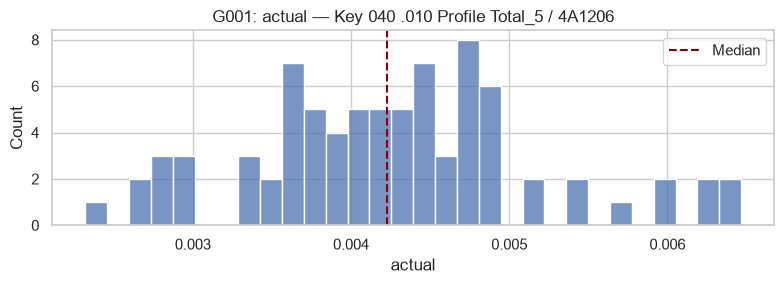

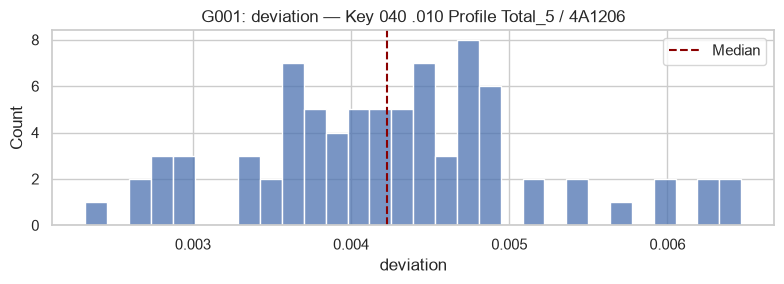

Chart context:

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
1,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


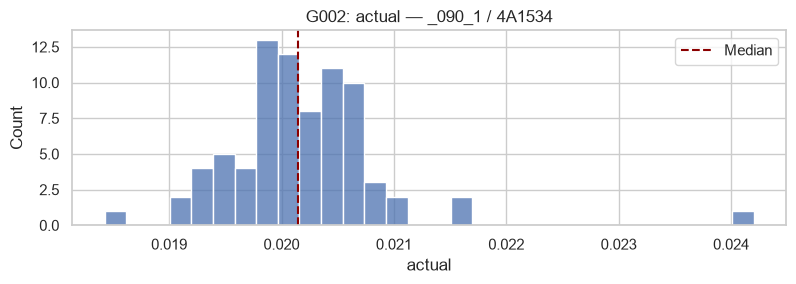

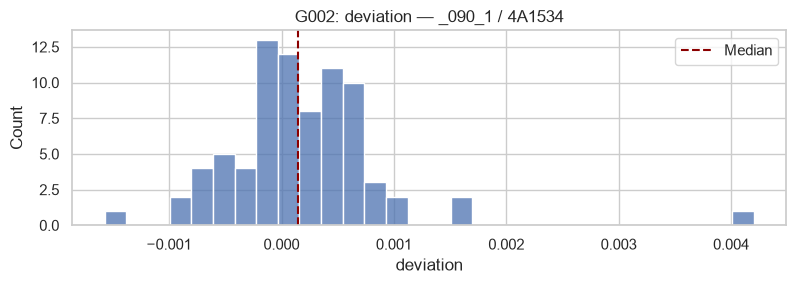

In [7]:
# Purpose: Plot a limited number of complete groups while retaining every group in the tables.
available_groups = group_summary.loc[group_summary.comparison_ready].sort_values(
    ["records", "group_id"], ascending=[False, True])
requested_ids = list(dict.fromkeys(PLOT_GROUP_IDS))
if requested_ids:
    plot_ids = [gid for gid in requested_ids if gid in set(available_groups.group_id)]
    print("Requested groups unavailable for plots:", [gid for gid in requested_ids if gid not in plot_ids] or "None")
else:
    plot_ids = available_groups.group_id.tolist()
plot_ids = plot_ids[:MAX_PLOT_GROUPS] if PLOT_COMBINATIONS else []
print("Groups selected for charts:", plot_ids or "None")
print("Group IDs identify this run's contexts; recheck them if you change the input data.")

for gid in plot_ids:
    current = group_data.loc[group_data.group_id.eq(gid)]
    print("Chart context:")
    display(group_lookup.loc[group_lookup.group_id.eq(gid)])
    for column in [c for c in ["actual", "deviation"] if c in current]:
        values = current[column].dropna()
        if not values.empty:
            plt.figure(figsize=(8, 3))
            sns.histplot(values, bins=30)
            plt.axvline(values.median(), color="darkred", linestyle="--", label="Median")
            plt.title(f"{gid}: {column} — {current.feature_name.iloc[0]} / {current.part_number.iloc[0]}")
            plt.legend(); plt.tight_layout(); plt.show()
            plt.close()


## 5. Categorical exploration

**Purpose:** See which vendors, features, parts, materials, and sizes are most common. Counts describe inspection records, not necessarily unique parts or production volume.

**Read the output:** Check dominant groups, rare labels, and missing categories. Tables and plots show at most 10 categories each; all values remain in the data. If a source pass/fail field exists, its labels are counted without validating them or calculating new outcomes.


,vendor_id,vendor_name
source_record,,
1,900001,SYNTHETIC VENDOR A
41,900002,SYNTHETIC VENDOR B


vendor_id: 2 distinct nonmissing values

,rows,percent
vendor_id,,
900001,80,50.0
900002,80,50.0


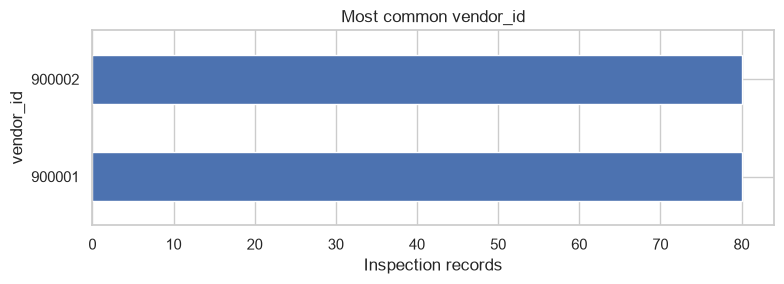

feature_type: 2 distinct nonmissing values

,rows,percent
feature_type,,
Inner Diameter,80,50.0
Profile,80,50.0


feature_name: 2 distinct nonmissing values

,rows,percent
feature_name,,
_090_1,80,50.0
Key 040 .010 Profile Total_5,80,50.0


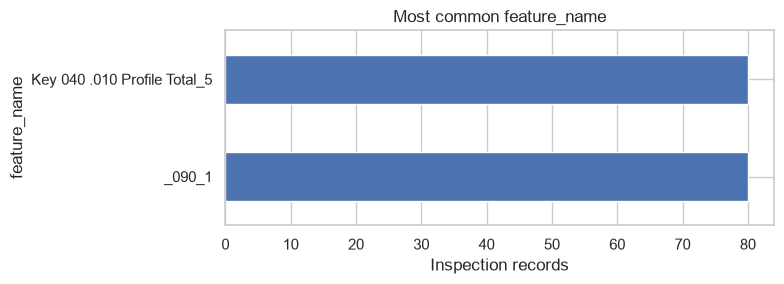

part_number: 2 distinct nonmissing values

,rows,percent
part_number,,
4A1534,80,50.0
4A1206,80,50.0


material_family: 1 distinct nonmissing values

,rows,percent
material_family,,
Steel,160,100.0


size: 2 distinct nonmissing values

,rows,percent
size,,
Micro,80,50.0
Small,80,50.0


commodity: 1 distinct nonmissing values

,rows,percent
commodity,,
MACHPARTS,160,100.0


In [8]:
# Purpose: Summarize category frequencies using vendor IDs when available.
vendor_column = "vendor_id" if "vendor_id" in df else "vendor_name"
if set(["vendor_id", "vendor_name"]).issubset(df.columns):
    display(df[["vendor_id", "vendor_name"]].drop_duplicates().head(20))
category_columns = [c for c in [vendor_column, "feature_type", "feature_name", "part_number",
                               "material_family", "size", "type", "commodity", "is_pass_fail"] if c in df]
for column in category_columns:
    counts = df[column].fillna("<MISSING>").value_counts(dropna=False)
    summary = counts.rename("rows").to_frame()
    summary["percent"] = (counts / len(df) * 100).round(1) if len(df) else np.nan
    print(f"{column}: {df[column].nunique()} distinct nonmissing values")
    display(summary.head(10))
    if column in [vendor_column, "feature_name"] and not counts.empty:
        counts.head(10).sort_values().plot.barh(figsize=(8, 3))
        plt.xlabel("Inspection records"); plt.title(f"Most common {column}")
        plt.tight_layout(); plt.show()


## 6. Basic relationships and time coverage

**Purpose:** Summarize every complete group by vendor. Each row of the vendor table is one vendor within one measurement group. Group IDs link back to Section 4's exact context.

The table covers all complete groups, including groups with only one vendor. Box plots use only the optional chart selection from Section 4 and require at least two vendors with usable measurements. Missing vendor IDs remain visible in the table as missing; they are excluded from vendor plots.

**Read the output:** Box plots show median, spread, and unusual points. They do not establish which vendor is better. Extra exact source copies and rows missing size have been removed. Other repeated inspections may remain. A group can have a valid descriptive summary without enough independent evidence for a vendor conclusion.

The time chart uses all cleaned records and shows inspection activity and gaps. It is not a process-control chart. Confirm date formats and timezone conventions before interpreting timing.


Vendor/group rows summarized: 4

,group_id,vendor_id,records,usable_measurements,mean,median,std,minimum,maximum,missing_measurements,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
0,G001,900001,40,40,0.004048,0.004142,0.000836,0.002319,0.006020,0,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
1,G001,900002,40,40,0.004467,0.004448,0.000902,0.002717,0.006466,0,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
2,G002,900001,40,38,0.020072,0.020068,0.000855,0.018428,0.024200,2,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
3,G002,900002,40,40,0.020308,0.020310,0.000529,0.019334,0.021601,0,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


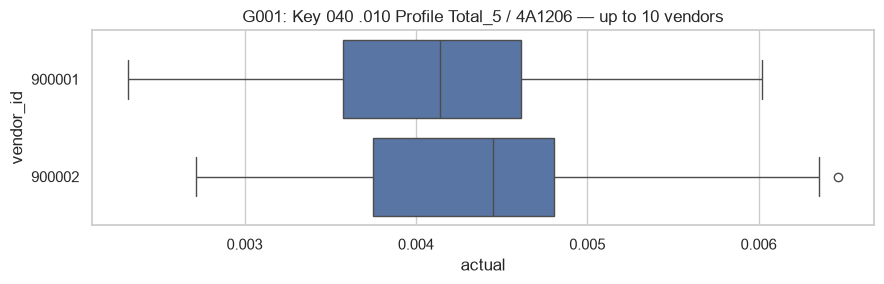

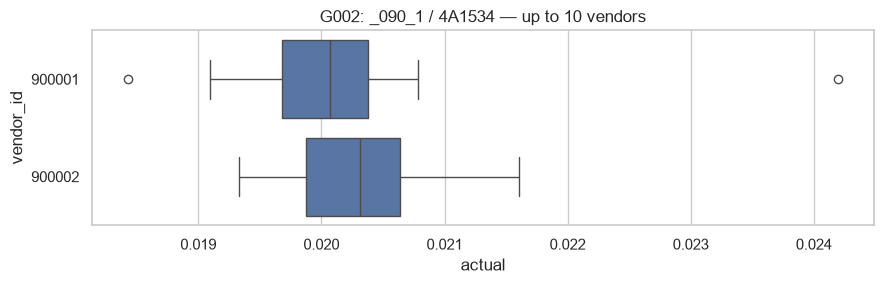

In [9]:
# Purpose: Summarize all complete groups by vendor, then plot only the selected groups.
ready_ids = set(group_summary.loc[group_summary.comparison_ready, "group_id"])
comparable_data = group_data.loc[group_data.group_id.isin(ready_ids)].copy()
vendor_summary = comparable_data.groupby(["group_id", "vendor_id"], dropna=False).agg(
    records=("actual", "size"), usable_measurements=("actual", "count"),
    mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
    minimum=("actual", "min"), maximum=("actual", "max"),
).reset_index()
vendor_summary["missing_measurements"] = vendor_summary.records-vendor_summary.usable_measurements
vendor_summary = vendor_summary.merge(group_lookup, on="group_id", how="left", validate="many_to_one")
print(f"Vendor/group rows summarized: {len(vendor_summary):,}")
display(vendor_summary.head(TABLE_PREVIEW_ROWS))

for gid in plot_ids:
    current = comparable_data.loc[comparable_data.group_id.eq(gid)].dropna(subset=["actual", "vendor_id"])
    if current.vendor_id.nunique() < 2:
        print(f"{gid}: vendor chart skipped; fewer than two vendors with usable measurements.")
        continue
    top_vendors = current.vendor_id.value_counts().head(10).index
    plot_data = current.loc[current.vendor_id.isin(top_vendors)]
    plt.figure(figsize=(9, max(3, len(top_vendors)*.45)))
    sns.boxplot(data=plot_data, x="actual", y="vendor_id", showfliers=True)
    plt.title(f"{gid}: {current.feature_name.iloc[0]} / {current.part_number.iloc[0]} — up to 10 vendors")
    plt.tight_layout(); plt.show()
    plt.close()


Date range:

2026-01-01 14:27:00

to

2026-04-28 14:27:00

Records without a valid date:

1

,inspection_records
date,
2026-01-01,43
2026-02-01,36
2026-03-01,40
2026-04-01,40


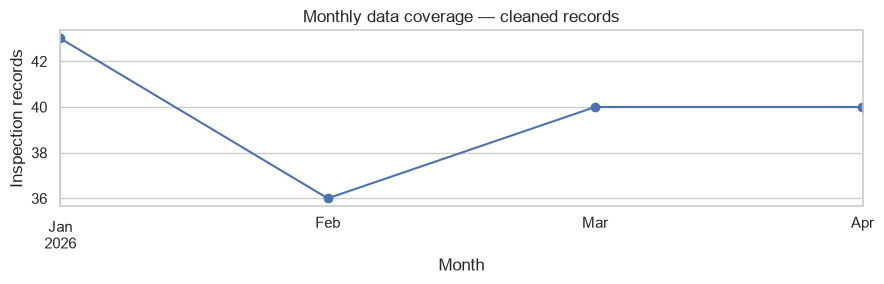

In [10]:
# Purpose: Show the date range and monthly inspection counts, including empty months.
monthly_counts = pd.Series(dtype="int64", name="inspection_records")
if "date" in df and pd.api.types.is_datetime64_any_dtype(df["date"]):
    dated = df.dropna(subset=["date"])
    if not dated.empty:
        print("Date range:", dated.date.min(), "to", dated.date.max())
        print("Records without a valid date:", int(df.date.isna().sum()))
        monthly_counts = dated.set_index("date").resample("MS").size().rename("inspection_records")
        display(monthly_counts.to_frame())
        monthly_counts.plot(figsize=(9, 3), marker="o")
        plt.ylabel("Inspection records"); plt.xlabel("Month")
        plt.title("Monthly data coverage — cleaned records")
        plt.tight_layout(); plt.show()
    else:
        print("No valid dates available.")
else:
    print("Time chart skipped: no usable date field; review its format/timezone if present.")


## 7. Unusual-record review

**Purpose:** Review the five smallest and five largest usable actual measurements **within every complete measurement group**, including groups not chosen for charts.

This is an investigation list, not an automatic outlier classification or specification-failure test. A record can be among a small group's extremes without being unusual. Groups with fewer than ten usable records may contribute all their records.

**Read the output:** `group_id` links to the context in Section 4; `source_record` and the available vendor, serial, date, work-order, and purchase-order fields trace the observation. This review does not remove additional records beyond the approved cleaning in Section 3. The notebook previews a limited number of rows and Section 8 exports the full review list.


In [11]:
# Purpose: Collect traceable low/high records from every complete group, independently of chart limits.
extreme_parts = []
for gid, current in comparable_data.dropna(subset=["actual"]).groupby("group_id"):
    extremes = pd.concat([current.nsmallest(5, "actual"), current.nlargest(5, "actual")])
    extremes = extremes.loc[~extremes.index.duplicated()].sort_values("actual")
    extreme_parts.append(extremes)
extremes = pd.concat(extreme_parts) if extreme_parts else comparable_data.iloc[:0].copy()
review_columns = ["group_id"]+COMPARISON_KEYS+["actual", "deviation", "vendor_id", "vendor_name",
                    "serial_no", "work_order", "po_number", "date"]
review_columns = list(dict.fromkeys(c for c in review_columns if c in extremes))
extreme_records = extremes[review_columns]
print(f"Extreme-record review: {len(extreme_records):,} records from {extreme_records.group_id.nunique():,} groups.")
display(extreme_records.head(TABLE_PREVIEW_ROWS))


Extreme-record review: 20 records from 2 groups.

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,deviation,vendor_id,vendor_name,serial_no,work_order,po_number,date
source_record,,,,,,,,,,,,,,,,,,
107,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002319,0.002319,900001,SYNTHETIC VENDOR A,000026,DEMO-WO-900001-2,005002,2026-03-20 14:27:00
105,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002697,0.002697,900001,SYNTHETIC VENDOR A,000024,DEMO-WO-900001-2,005002,2026-03-14 14:27:00
131,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002717,0.002717,900002,SYNTHETIC VENDOR B,000010,DEMO-WO-900002-1,005001,2026-01-31 14:27:00
101,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002759,0.002759,900001,SYNTHETIC VENDOR A,000020,DEMO-WO-900001-2,005002,2026-03-02 14:27:00
102,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002790,0.002790,900001,SYNTHETIC VENDOR A,000021,DEMO-WO-900001-2,005002,2026-03-05 14:27:00
112,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006020,0.006020,900001,SYNTHETIC VENDOR A,000031,DEMO-WO-900001-3,005003,2026-04-04 14:27:00
145,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006202,0.006202,900002,SYNTHETIC VENDOR B,000024,DEMO-WO-900002-2,005002,2026-03-14 14:27:00
155,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006326,0.006326,900002,SYNTHETIC VENDOR B,000034,DEMO-WO-900002-3,005003,2026-04-13 14:27:00
122,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006353,0.006353,900002,SYNTHETIC VENDOR B,000001,DEMO-WO-900002-0,005000,2026-01-04 14:27:00


## 8. Initial findings and next steps

**Purpose:** Record the main observations and save the complete tables. Chart and preview limits do not limit exported data.

1. **Scope:** The original file contains ___ rows; approved cleaning retains ___ rows, ___ exploration combinations, and ___ measurement groups. One row represents ___.
2. **Cleaning and data quality:** Removed ___ extra exact copies and ___ additional missing-size rows; filled ___ retained unit labels with Standard. Remaining parsing or context issues are ___.
3. **Coverage:** Most records come from ___. Groups with limited vendor coverage or changing specifications are ___.
4. **Measurements:** Groups ___ deserve investigation because their typical values, spread, or extremes show ___.
5. **Relationships:** Possible vendor or time patterns are ___. These are provisional because ___.
6. **Next steps:** Confirm ___ with the data owner, investigate source records ___, and then consider ___ for deeper analysis.

The export cell saves `combination_inventory.csv`, `group_statistics.csv`, `vendor_group_statistics.csv`, and `extreme_records.csv` in `SUMMARY_FOLDER`. Incomplete groups remain in the first two files with their status. These summary files are refreshed on each run; the input CSV is never changed. IDs and record-review files should be stored with the same access restrictions as the input.

**Done for initial EDA:** You can describe the dataset, locate every measurement context, identify quality concerns, and choose questions for deeper analysis. No formal vendor ranking or statistical testing is performed here.


In [12]:
# Purpose: Save full tables so previews and chart limits do not hide combinations.
if EXPORT_TABLES:
    SUMMARY_FOLDER.mkdir(parents=True, exist_ok=True)
    full_tables = {"combination_inventory.csv": combination_inventory,
                   "group_statistics.csv": group_summary,
                   "vendor_group_statistics.csv": vendor_summary,
                   "extreme_records.csv": extreme_records.reset_index()}
    for filename, table in full_tables.items():
        target = SUMMARY_FOLDER / filename
        if target.resolve() == CSV_PATH.resolve():
            raise ValueError("Choose a summary folder that does not overwrite the input CSV.")
        table.to_csv(target, index=False)
    print("Full tables saved to:", SUMMARY_FOLDER.resolve())
else:
    print("Exports disabled. Full tables remain available as DataFrames in this notebook session.")


Full tables saved to:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\initial_eda_summaries

# Part II

**Basic follow-up checks and first vendor comparison**

Run Part I first, or choose **Restart Kernel → Run All**. Both parts use the same approved cleaned dataset: extra exact source copies removed, empty units filled with Standard, missing-size rows dropped, and deviation recalculated as actual minus nominal. Changing specifications remain separate.

Sections 1-2 use explicitly labeled source audit tables to explain removals and assumptions. Section 4 compares before duplicate removal with the cleaned data within the same retained eligible contexts. All group, outlier, time, and vendor analyses use cleaned records. Other repeated inspections can remain; retained records are not automatically independent.

Only four complete Part II review tables are exported: duplicate evidence, missing-context records, group before/after statistics, and flagged measurements. Part I's four summaries remain separate. Table and chart limits never truncate the underlying exported tables. The saved local run uses the synthetic CSV; select your Optimus export to analyze production data.


In [13]:
# Purpose: Reuse cleaned analysis records and keep the original-row audit explicitly separate.
MIN_REVIEW_RECORDS = 10
PART_II_FOLDER = SUMMARY_FOLDER / "part_ii"
if not isinstance(MIN_REVIEW_RECORDS, int) or MIN_REVIEW_RECORDS < 2:
    raise ValueError("MIN_REVIEW_RECORDS must be an integer of at least 2.")
if not df.index.equals(group_data.index) or not df_raw.index.equals(group_data_preclean.index):
    raise ValueError("Restart and run Part I so source, audit, and cleaned records align.")
p2_audit = group_data_preclean.copy()
p2_audit["extra_exact_copy"] = cleaning_audit.extra_exact_copy
p2_audit["included_in_analysis"] = cleaning_audit.included_in_analysis
p2_audit["cleaning_status"] = cleaning_audit.cleaning_status
p2_clean = p2_audit.loc[df.index].drop(columns=empty_columns).copy()
print("Input:", CSV_PATH.resolve())
print(f"Original rows for audit: {len(p2_audit):,}; cleaned rows for analysis: {len(p2_clean):,}.")

P2_PLOTS = True
P2_PLOT_GROUP_ID = None  # Optional G... ID; otherwise largest eligible cleaned group.


Input:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\example_manufacturing_measurements.csv

Original rows for audit: 162; cleaned rows for analysis: 160.

## 1. Audit removed exact copies by vendor, part, and month

**What we do:** Count extra copies in the original source, show where they occurred, and put all matching records together. Exact matching uses every original CSV column before cleaning. These copies have already been removed from analysis in Part I, Section 3.

**How to read it:** `copies_in_set` includes the first occurrence; `extra_exact_copy=True` marks later copies. `included_in_analysis` and `cleaning_status` show the final decision, because even a first occurrence can be excluded for missing size. Each vendor/part/month percentage uses the original record count for that category. This is an audit of the input, not the composition of the cleaned dataset.

Repeating only a vendor ID, part number, or inspection key is not an exact-copy match. The bar chart shows original duplication concentration, not vendor quality. The complete evidence table is exported to document the authorized removals.


In [14]:
# Purpose: Count exact copies and show their source records together.
p2_extra_n = int(p2_audit.extra_exact_copy.sum())
print("Extra exact copies:", p2_extra_n)
print("Extra-copy percentage:", round(100 * p2_extra_n / len(p2_audit), 2) if len(p2_audit) else "N/A")
p2_audit["year_month"] = p2_audit.date.dt.to_period("M").astype("string")
for p2_column in ["vendor_id", "part_number", "year_month"]:
    p2_breakdown = p2_audit.groupby(p2_column, dropna=False).agg(
        records=("actual", "size"), extra_copies=("extra_exact_copy", "sum")).reset_index()
    p2_breakdown["extra_copy_percent"] = 100 * p2_breakdown.extra_copies / p2_breakdown.records
    print("Duplicates by", p2_column)
    display(p2_breakdown.sort_values("extra_copies", ascending=False).head(TABLE_PREVIEW_ROWS))

p2_members = df_raw.loc[df_raw.duplicated(keep=False)]
p2_duplicate_evidence = p2_members.copy()
p2_duplicate_evidence.insert(0, "source_record", p2_members.index)
if not p2_members.empty:
    p2_duplicate_evidence["duplicate_set"] = p2_members.groupby(
        list(df_raw.columns), dropna=False, sort=False).ngroup().to_numpy() + 1
    p2_sets = p2_duplicate_evidence.groupby("duplicate_set")
    p2_duplicate_evidence["first_source_record"] = p2_sets.source_record.transform("min")
    p2_duplicate_evidence["copies_in_set"] = p2_sets.source_record.transform("size")
else:
    for p2_column in ["duplicate_set", "first_source_record", "copies_in_set"]:
        p2_duplicate_evidence[p2_column] = pd.Series(dtype="int64")
p2_duplicate_evidence["extra_exact_copy"] = p2_audit.loc[p2_members.index, "extra_exact_copy"]
p2_duplicate_evidence["included_in_analysis"] = cleaning_audit.loc[p2_members.index, "included_in_analysis"]
p2_duplicate_evidence["cleaning_status"] = cleaning_audit.loc[p2_members.index, "cleaning_status"]
p2_duplicate_evidence = p2_duplicate_evidence.reset_index(drop=True).sort_values(["duplicate_set", "source_record"])
print("All members of exact-match sets:", len(p2_duplicate_evidence), "(preview below)")
display(p2_duplicate_evidence.head(TABLE_PREVIEW_ROWS))


Extra exact copies:

2

Extra-copy percentage:

1.23

Duplicates by

vendor_id

... (7 outputs left out)

All members of exact-match sets:

4

(preview below)

,source_record,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,...,date,work_order,po_number,vendor_id,vendor_name,commodity,duplicate_set,first_source_record,copies_in_set,extra_exact_copy,included_in_analysis,cleaning_status
0,13,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,...,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS,1,13,2,False,True,retained
2,161,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,...,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS,1,13,2,True,False,removed: extra exact copy
1,59,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,...,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS,2,59,2,False,True,retained
3,162,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,...,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS,2,59,2,True,False,removed: extra exact copy


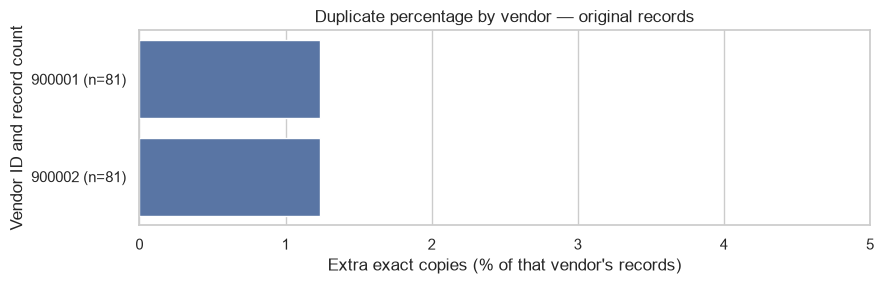

In [15]:
# Purpose: Make duplicate concentration easy to compare while showing category sizes.
p2_vendor_rates = p2_audit.groupby("vendor_id", dropna=False).agg(
    records=("actual", "size"), extra_copies=("extra_exact_copy", "sum")).reset_index()
p2_vendor_rates["extra_copy_percent"] = 100 * p2_vendor_rates.extra_copies / p2_vendor_rates.records
p2_vendor_rates = p2_vendor_rates.sort_values("extra_copy_percent", ascending=False)
p2_vendor_rates["vendor_label"] = [f"{vendor if pd.notna(vendor) else '<MISSING>'} (n={int(count):,})"
    for vendor, count in zip(p2_vendor_rates.vendor_id, p2_vendor_rates.records)]
if P2_PLOTS and not p2_vendor_rates.empty:
    plt.figure(figsize=(9, max(3, .4 * len(p2_vendor_rates))))
    sns.barplot(data=p2_vendor_rates, x="extra_copy_percent", y="vendor_label",
                order=p2_vendor_rates.vendor_label.tolist(), color="#4C72B0", errorbar=None)
    plt.xlim(0, max(5, p2_vendor_rates.extra_copy_percent.max() * 1.1))
    plt.xlabel("Extra exact copies (% of that vendor's records)"); plt.ylabel("Vendor ID and record count")
    plt.title("Duplicate percentage by vendor — original records")
    plt.tight_layout(); plt.show(); plt.close()
elif P2_PLOTS:
    print("Duplicate percentage chart skipped: no records available.")


## 2. Audit unit assumptions, dropped sizes, and remaining missing context

**What we do:** Show original and cleaned unit labels, the number assigned Standard, rows removed for missing size, and remaining incomplete comparison fields.

An empty or whitespace-only unit means Standard under the agreed rule. A missing size excludes the entire row from all analyses. The original unit, assumption flag, and source-record number remain available for traceability. Other missing comparison fields still block the affected comparisons. Standard and Metric remain labels without physical-unit conversion.

`missing_context_records.csv` documents original rows with missing size or other unresolved context after unit filling, including their final cleaning decision. A row included in this audit is not necessarily included in analysis. Unit-only omissions that were resolved by Standard do not count as remaining missing context. The retained-data table below shows current missingness.


In [16]:
# Purpose: Distinguish original missing values, applied assumptions, and remaining issues.
print("Original unit labels (source audit):")
display(p2_audit.source_unit.value_counts(dropna=False).rename("original_records").to_frame())
print("Unit labels in cleaned analysis data:")
display(p2_clean.unit.value_counts(dropna=False).rename("cleaned_records").to_frame())
print("Standard assigned among cleaned rows:", int(p2_clean.unit_assumed_standard.sum()))
print("Original missing-size rows (including duplicate overlap):", int(cleaning_audit.missing_size.sum()))
print("Additional missing-size rows removed after duplicates:", int(cleaning_audit.cleaning_status.eq("removed: missing size").sum()))
p2_missing = p2_clean[COMPARISON_KEYS].isna().sum().rename("missing_records").to_frame()
p2_missing["missing_percent"] = 100 * p2_missing.missing_records / len(p2_clean) if len(p2_clean) else np.nan
print("Remaining missing comparison context in cleaned records:")
display(p2_missing)

p2_trace_columns = [c for c in ["actual", "vendor_id", "vendor_name", "serial_no", "work_order", "date",
    "source_unit", "unit_assumed_standard", "included_in_analysis", "cleaning_status"] if c in p2_audit]
p2_context_records = p2_audit.loc[p2_audit.context_missing, ["group_id"] + COMPARISON_KEYS + p2_trace_columns].copy()
p2_context_fields = audit_group_lookup.set_index("group_id")[COMPARISON_KEYS].apply(
    lambda row: ", ".join(row.index[row.isna()]), axis=1) if len(audit_group_lookup) else pd.Series(dtype="string")
p2_context_records["missing_context_fields"] = p2_context_records.group_id.map(p2_context_fields)
p2_context_records = p2_context_records.rename_axis("source_record").reset_index()
print("Source records with missing size or unresolved context after unit filling (audit):", len(p2_context_records))
display(p2_context_records.head(TABLE_PREVIEW_ROWS))


Original unit labels (source audit):

,original_records
source_unit,
Standard,162


Unit labels in cleaned analysis data:

,cleaned_records
unit,
Standard,160


Standard assigned among cleaned rows:

0

... (5 outputs left out)

,missing_records,missing_percent
feature_name,0,0.0
part_number,0,0.0
unit,0,0.0
feature_type,0,0.0
material_family,0,0.0
size,0,0.0
nominal,0,0.0
upper_tolerance,0,0.0
lower_tolerance,0,0.0


Source records with missing size or unresolved context after unit filling (audit):

0

,source_record,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,vendor_id,vendor_name,serial_no,work_order,date,source_unit,unit_assumed_standard,included_in_analysis,cleaning_status,missing_context_fields


## 3. Check small groups and legitimate specification differences

Count usable measurements per cleaned group. The specification inventory also uses cleaned records. Changing nominal and tolerance values are assumed to represent legitimate differences, so the notebook keeps them separate without rounding or combining them.

One measurement cannot estimate sample standard deviation. Even with many records overall, detailed specification groups can be small. A descriptive summary is not proof of adequate sample size or independent observations. These checks introduce no further exclusions.


In [17]:
# Purpose: Identify small groups and specification variation without adding grouping strategies.
p2_group_sizes = p2_clean.groupby("group_id").agg(
    retained_records=("actual", "size"), usable_actual=("actual", "count")).reset_index()
p2_group_sizes = p2_group_sizes.merge(
    group_summary[["group_id", "feature_name", "part_number", "status"]], on="group_id", validate="one_to_one")
print("Groups with no usable actual values:", int(p2_group_sizes.usable_actual.eq(0).sum()))
print("Groups with one usable actual value:", int(p2_group_sizes.usable_actual.eq(1).sum()))
print(f"Groups with 2 to {MIN_REVIEW_RECORDS - 1} usable values:",
      int(p2_group_sizes.usable_actual.between(2, MIN_REVIEW_RECORDS - 1).sum()))
print("Smallest groups (including incomplete contexts):")
display(p2_group_sizes.sort_values("usable_actual").head(TABLE_PREVIEW_ROWS))
print("Combinations with the most specification variants; record counts here use cleaned data:")
display(combination_inventory.sort_values("specification_variants", ascending=False)[
    EXPLORATION_KEYS + ["records", "specification_variants", "comparison_groups"]].head(TABLE_PREVIEW_ROWS))


Groups with no usable actual values:

0

Groups with one usable actual value:

0

Groups with 2 to 9 usable values:

0

Smallest groups (including incomplete contexts):

,group_id,retained_records,usable_actual,feature_name,part_number,status
1,G002,80,78,_090_1,4A1534,descriptive summary available
0,G001,80,80,Key 040 .010 Profile Total_5,4A1206,descriptive summary available


Combinations with the most specification variants; record counts here use cleaned data:

,feature_name,part_number,unit,records,specification_variants,comparison_groups
0,Key 040 .010 Profile Total_5,4A1206,Standard,80,1,1
1,_090_1,4A1534,Standard,80,1,1


## 4. Audit group statistics before and after approved duplicate removal

**What we do:** Compare pre-removal rows with the cleaned dataset within the same retained, eligible measurement contexts. Standard filling and deviation recalculation are applied to both sides for consistent definitions. Contexts with missing size have already been excluded from analysis and are documented in the cleaning summary and missing-context audit, not this comparison.

**How to read it:** Columns ending `_original` describe those contexts before duplicate removal; `_cleaned` columns describe the cleaned analysis rows. `copies_removed` is the count of extra exact source copies removed from each eligible group. Changes equal cleaned minus original. These group totals do not necessarily cover the entire input; use Section 3's cleaning summary for full reconciliation.

The two-panel histogram uses 12 common intervals and matching axes. Each panel totals 100%. A bar at 10% contains one tenth of that panel's measurements; the dashed line marks the median. Counts can change substantially while shapes remain similar. If no usable copies were removed, the panels are identical. These are versions of the same records, not independent samples or pass/fail results.

`P2_PLOT_GROUP_ID=None` selects the largest eligible cleaned group. Both Parts I and II already use the cleaned data; this before/after display is a removal audit only.


In [18]:
# Purpose: Reuse one basic summary calculation for a clear before/after comparison.
p2_ready_ids = set(group_summary.loc[group_summary.comparison_ready, "group_id"])
p2_before = p2_audit.loc[p2_audit.group_id.isin(p2_ready_ids)]
p2_after = p2_clean.loc[p2_clean.group_id.isin(p2_ready_ids)]

def p2_basic_summary(frame):
    return frame.groupby("group_id").agg(
        records=("actual", "size"), usable_actual=("actual", "count"),
        mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
        minimum=("actual", "min"), maximum=("actual", "max")).reset_index()

p2_original_stats = p2_basic_summary(p2_before)
p2_cleaned_stats = p2_basic_summary(p2_after)
p2_changes = p2_original_stats.merge(p2_cleaned_stats, on="group_id",
    suffixes=("_original", "_cleaned"), validate="one_to_one")
p2_changes["copies_removed"] = p2_changes.records_original - p2_changes.records_cleaned
p2_changes["mean_change"] = p2_changes.mean_cleaned - p2_changes.mean_original
p2_changes["median_change"] = p2_changes.median_cleaned - p2_changes.median_original
p2_changes = p2_changes.merge(group_lookup, on="group_id", validate="one_to_one").sort_values("copies_removed", ascending=False)
display(p2_changes.head(TABLE_PREVIEW_ROWS))


,group_id,records_original,usable_actual_original,mean_original,median_original,std_original,minimum_original,maximum_original,records_cleaned,usable_actual_cleaned,mean_cleaned,median_cleaned,...,copies_removed,mean_change,median_change,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
1,G002,82,80,0.020200,0.020153,0.000704,0.018428,0.024200,80,78,0.020193,0.020149,...,2,-0.000006,-0.000005,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
0,G001,80,80,0.004257,0.004229,0.000890,0.002319,0.006466,80,80,0.004257,0.004229,...,0,0.000000,0.000000,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000


,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
81,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.0,0.01,0.0


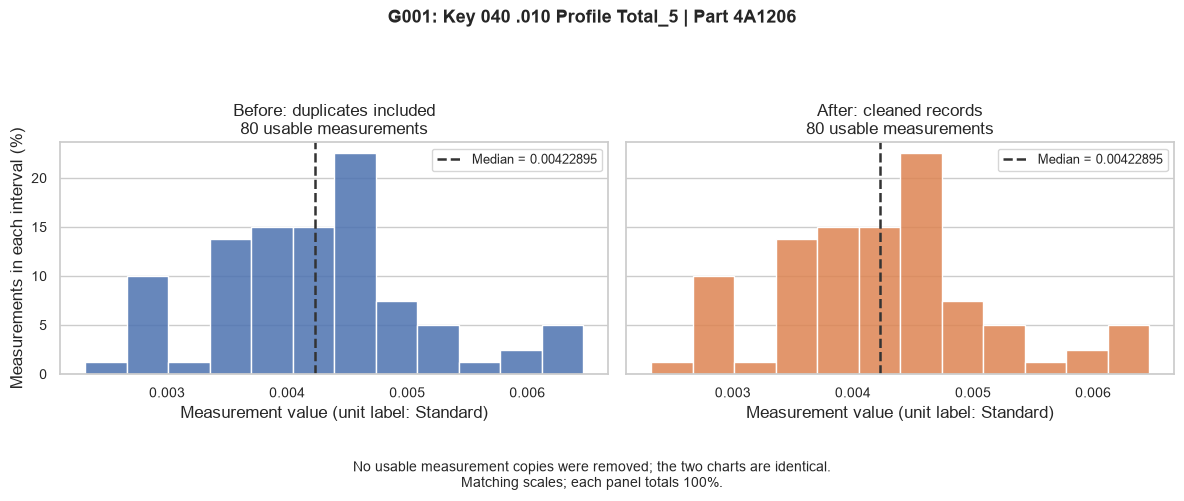

How to read: each bar groups nearby measurement values. A height of 10% means

10% of that panel's usable measurements fall in that interval.

The dashed line is the median: half the values are at or below it and half at or above it.

These charts show distribution shape, not specification pass/fail.

In [19]:
# Purpose: Compare distribution shapes within one consistent measurement context.
p2_plot_options = p2_cleaned_stats.loc[p2_cleaned_stats.usable_actual >= 2].sort_values(
    ["usable_actual", "group_id"], ascending=[False, True])
p2_plot_id = P2_PLOT_GROUP_ID
if p2_plot_id is None and not p2_plot_options.empty:
    p2_plot_id = p2_plot_options.group_id.iloc[0]
if p2_plot_id not in set(p2_plot_options.group_id):
    if P2_PLOTS:
        print("Measurement plots skipped: requested group unavailable, incomplete, or below two usable values.")
    p2_plot_id = None

p2_hist_data = pd.DataFrame(columns=["actual", "scenario"])
if P2_PLOTS and p2_plot_id is not None:
    display(group_lookup.loc[group_lookup.group_id.eq(p2_plot_id)])
    p2_original_values = p2_before.loc[p2_before.group_id.eq(p2_plot_id), "actual"].dropna()
    p2_cleaned_values = p2_after.loc[p2_after.group_id.eq(p2_plot_id), "actual"].dropna()
    p2_original_label = f"Original (n={len(p2_original_values):,})"
    p2_cleaned_label = f"Cleaned (n={len(p2_cleaned_values):,})"
    p2_hist_data = pd.concat([
        p2_original_values.to_frame().assign(scenario=p2_original_label),
        p2_cleaned_values.to_frame().assign(scenario=p2_cleaned_label)], ignore_index=True)
    # Use the same 12 intervals and axis scales so the panels compare fairly.
    p2_bins = np.histogram_bin_edges(p2_original_values, bins=12)
    p2_context = group_lookup.loc[group_lookup.group_id.eq(p2_plot_id)].iloc[0]
    p2_removed_usable = len(p2_original_values) - len(p2_cleaned_values)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for ax, values, title, color in zip(
        axes, [p2_original_values, p2_cleaned_values],
        ["Before: duplicates included", "After: cleaned records"],
        ["#4C72B0", "#DD8452"]):
        sns.histplot(x=values, bins=p2_bins, stat="percent", color=color,
                     edgecolor="white", alpha=0.85, ax=ax)
        median = values.median()
        ax.axvline(median, color="#333333", linestyle="--", linewidth=1.8,
                   label=f"Median = {median:.6g}")
        ax.set_title(f"{title}\n{len(values):,} usable measurements", fontsize=12)
        ax.set_xlabel(f"Measurement value (unit label: {p2_context['unit']})")
        ax.set_ylabel("Measurements in each interval (%)")
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
        ax.tick_params(axis="both", labelsize=10)
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
        ax.legend(loc="upper right", fontsize=9)
    from textwrap import fill
    fig.suptitle(fill(f"{p2_plot_id}: {p2_context['feature_name']} | Part {p2_context['part_number']}", 90),
                 fontsize=13, fontweight="bold")
    p2_hist_note = ("No usable measurement copies were removed; the two charts are identical."
                    if p2_removed_usable == 0 else
                    f"{p2_removed_usable:,} usable measurement copies removed. Compare the shape and median across panels.")
    fig.text(0.5, 0.025, p2_hist_note + "\nMatching scales; each panel totals 100%.",
             ha="center", fontsize=10)
    fig.tight_layout(rect=[0, 0.12, 1, 0.9])
    plt.show(); plt.close()
    print("How to read: each bar groups nearby measurement values. A height of 10% means")
    print("10% of that panel's usable measurements fall in that interval.")
    print("The dashed line is the median: half the values are at or below it and half at or above it.")
    print("These charts show distribution shape, not specification pass/fail.")


## 5. Check unusual measurements and basic vendor differences

Apply the IQR rule to eligible cleaned groups: flag values below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR`, where Q1 and Q3 bound the middle 50% of measurements. Require at least `MIN_REVIEW_RECORDS` usable measurements and a positive IQR. Small or zero-IQR groups are explicitly not screened.

Flags are review candidates, not errors or specification failures. No additional rows are removed by this review. Exact source copies and missing-size rows were removed centrally; other repeated inspections may remain.

The vendor table and time scatter plot use cleaned data. Compare vendors only within a consistent group and consider sample sizes, dates, and inspection conditions. The scatter plot shares the histogram's group and reports unusable dates/measurements. If more than 5,000 usable dated records exist, it displays a reproducible 5,000-row sample; tables and exports still use all applicable cleaned records. No significance test, vendor ranking, or claim of process stability is made.


In [20]:
# Purpose: Apply one IQR rule and show a basic within-group vendor summary.
p2_quartiles = p2_after.groupby("group_id")["actual"].quantile([.25, .75]).unstack(-1)
p2_quartiles = p2_quartiles.reindex(columns=[.25, .75]).rename(columns={.25: "q1", .75: "q3"})
p2_screen = p2_cleaned_stats[["group_id", "usable_actual"]].merge(
    p2_quartiles.reset_index(), on="group_id", validate="one_to_one")
p2_screen["iqr"] = p2_screen.q3 - p2_screen.q1
p2_screen["status"] = np.select(
    [p2_screen.usable_actual.lt(MIN_REVIEW_RECORDS), p2_screen.iqr.isna() | p2_screen.iqr.le(0)],
    ["not screened: too few values", "not screened: zero or undefined IQR"], default="screened")
p2_screen["iqr_lower"] = p2_screen.q1 - 1.5 * p2_screen.iqr
p2_screen["iqr_upper"] = p2_screen.q3 + 1.5 * p2_screen.iqr
p2_screen.loc[p2_screen.status.ne("screened"), ["iqr_lower", "iqr_upper"]] = np.nan
print("IQR screening coverage (eligible groups only):")
display(p2_screen.status.value_counts().rename("groups").to_frame())

p2_candidates = p2_after.rename_axis("source_record").reset_index().merge(
    p2_screen[["group_id", "iqr_lower", "iqr_upper"]], on="group_id", validate="many_to_one")
p2_flagged = p2_candidates.loc[p2_candidates.actual.lt(p2_candidates.iqr_lower) |
    p2_candidates.actual.gt(p2_candidates.iqr_upper)].copy()
p2_flagged["review_reason"] = np.where(p2_flagged.actual < p2_flagged.iqr_lower, "below IQR fence", "above IQR fence")
p2_review_columns = ["source_record", "group_id"] + COMPARISON_KEYS + [c for c in
    ["actual", "deviation", "vendor_id", "vendor_name", "serial_no", "work_order", "po_number", "date"] if c in p2_flagged]
p2_flagged = p2_flagged[p2_review_columns + ["iqr_lower", "iqr_upper", "review_reason"]].sort_values(["group_id", "actual"])
print("Flagged measurements:", len(p2_flagged), "(preview below; these are not failure counts)")
display(p2_flagged.head(TABLE_PREVIEW_ROWS))

p2_vendors = p2_after.groupby(["group_id", "vendor_id"], dropna=False).agg(
    records=("actual", "size"), usable_actual=("actual", "count"),
    median=("actual", "median"), std=("actual", "std")).reset_index()
p2_vendors["count_note"] = np.where(p2_vendors.usable_actual < MIN_REVIEW_RECORDS,
    "small sample: interpret cautiously", "descriptive only; independence unverified")
p2_vendors = p2_vendors.merge(group_lookup, on="group_id", validate="many_to_one")
print("Vendor summary using cleaned records (missing vendor IDs remain visible):")
display(p2_vendors.head(TABLE_PREVIEW_ROWS))


IQR screening coverage (eligible groups only):

,groups
status,
screened,2


Flagged measurements:

7

(preview below; these are not failure counts)

,source_record,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,deviation,vendor_id,vendor_name,serial_no,work_order,po_number,date,iqr_lower,iqr_upper,review_reason
154,155,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006326,0.006326,900002,SYNTHETIC VENDOR B,000034,DEMO-WO-900002-3,005003,2026-04-13 14:27:00,0.002126,0.006267,above IQR fence
121,122,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006353,0.006353,900002,SYNTHETIC VENDOR B,000001,DEMO-WO-900002-0,005000,2026-01-04 14:27:00,0.002126,0.006267,above IQR fence
136,137,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006466,0.006466,900002,SYNTHETIC VENDOR B,000016,DEMO-WO-900002-1,005001,2026-02-18 14:27:00,0.002126,0.006267,above IQR fence
32,33,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.018428,-0.001572,900001,SYNTHETIC VENDOR A,000032,DEMO-WO-900001-3,005003,2026-04-07 14:27:00,0.018829,0.021535,below IQR fence
71,72,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.021593,0.001593,900002,SYNTHETIC VENDOR B,000031,DEMO-WO-900002-3,005003,2026-04-04 14:27:00,0.018829,0.021535,above IQR fence
53,54,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.021601,0.001601,900002,SYNTHETIC VENDOR B,000013,DEMO-WO-900002-1,005001,2026-02-09 14:27:00,0.018829,0.021535,above IQR fence
5,6,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.024200,0.004200,900001,SYNTHETIC VENDOR A,000005,DEMO-WO-900001-0,005000,2026-01-16 14:27:00,0.018829,0.021535,above IQR fence


Vendor summary using cleaned records (missing vendor IDs remain visible):

,group_id,vendor_id,records,usable_actual,median,std,count_note,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
0,G001,900001,40,40,0.004142,0.000836,descriptive only; independence unverified,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
1,G001,900002,40,40,0.004448,0.000902,descriptive only; independence unverified,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
2,G002,900001,40,38,0.020068,0.000855,descriptive only; independence unverified,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
3,G002,900002,40,40,0.020310,0.000529,descriptive only; independence unverified,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


Records excluded from this time plot for missing actual/date:

0

Time plot: 80 of 80 dated usable measurements.

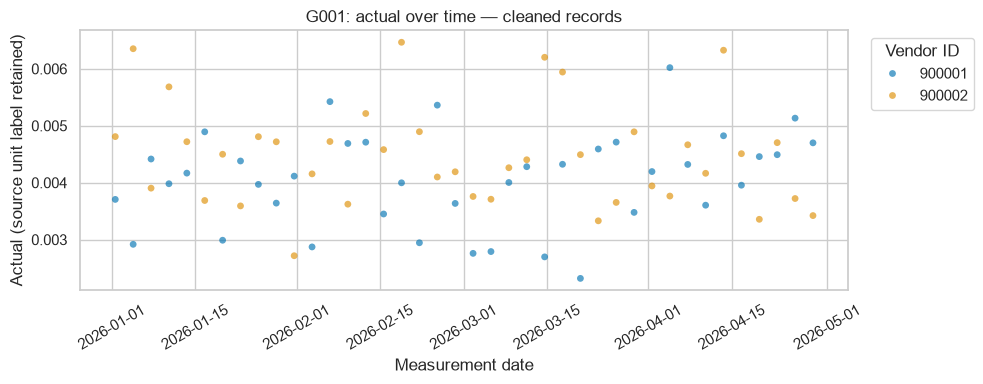

In [21]:
# Purpose: Look for time patterns and differing vendor coverage within the same group.
p2_time_data = p2_after.iloc[:0].copy()
p2_time_plot = p2_time_data.copy()
if P2_PLOTS and p2_plot_id is not None:
    p2_selected = p2_after.loc[p2_after.group_id.eq(p2_plot_id)]
    p2_time_data = p2_selected.dropna(subset=["actual", "date"]).copy()
    print("Records excluded from this time plot for missing actual/date:", len(p2_selected) - len(p2_time_data))
    if p2_time_data.empty:
        print("Time scatter plot skipped: no usable actual/date pairs in the selected group.")
    else:
        p2_time_plot = p2_time_data.sample(n=5000, random_state=42) if len(p2_time_data) > 5000 else p2_time_data.copy()
        p2_time_plot["vendor_label"] = p2_time_plot.vendor_id.fillna("<MISSING>").astype(str)
        p2_sample_note = " (random sample)" if len(p2_time_plot) < len(p2_time_data) else ""
        print(f"Time plot: {len(p2_time_plot):,} of {len(p2_time_data):,} dated usable measurements{p2_sample_note}.")
        plt.figure(figsize=(10, 4))
        sns.scatterplot(data=p2_time_plot, x="date", y="actual", hue="vendor_label",
                        palette="colorblind", alpha=.65, s=24, linewidth=0)
        plt.xlabel("Measurement date"); plt.ylabel("Actual (source unit label retained)")
        plt.title(f"{p2_plot_id}: actual over time — cleaned records{p2_sample_note}")
        plt.legend(title="Vendor ID", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=30); plt.tight_layout(); plt.show(); plt.close()


## 6. First vendor comparison: deviations within one measurement context

**Purpose:** Compare vendors for one feature type, material, size, part, specific feature, unit, and specification context.

This section reuses the same cleaned data as every other analysis: extra exact source copies removed, empty unit labels filled with Standard and flagged, missing-size rows dropped, and deviation calculated as actual minus nominal. Legitimate specification differences remain separate. No additional unit filling, duplicate removal, or alternative grouping occurs here.

**Enough information:** Require an eligible complete context, finite actual/deviation values, and a vendor ID. Dates are optional for histograms and their coverage is summarized. `vc_records` identifies comparison eligibility for every cleaned source record; `vc_not_ready` lists remaining blockers. A row with several problems shows its first blocking reason. Excluded source rows remain only in `cleaning_audit` and the dedicated source audits.

Select a context with at least two vendors having 10 usable measurements each, largest qualifying total first. Vendors below the threshold remain visible in the count table but are omitted from the plot. The threshold is a practical starting rule, not proof of adequacy or independence. `FIRST_COMPARISON_ID` can select a `G...` ID from `vc_candidates`; these are the same group IDs used throughout this run. IDs can change with the input.

Each vendor panel uses the same 12 intervals and matching scales, totaling 100% separately. A dashed line marks the median and a dotted line marks zero. Under the agreed calculation, left/right of zero means below/above nominal; geometric features with nominal zero may have only nonnegative values. Compare center, spread, and tails alongside counts and date ranges. Peaks are not forced to equal height. No vendor ranking, pass/fail conclusion, or additional CSV export is produced.


In [22]:
# Purpose: Identify vendor-comparison eligibility within the shared cleaned dataset.
FIRST_COMPARISON_ID = None  # Optional: choose a G... ID from vc_candidates for this input.
MIN_VENDOR_MEASUREMENTS = 10

vc_records = p2_clean.copy()
vc_records["calculated_deviation"] = vc_records["deviation"]
vc_context_ok = vc_records[COMPARISON_KEYS].notna().all(axis=1) & vc_records.group_id.isin(p2_ready_ids)
vc_measurement_ok = np.isfinite(vc_records["actual"]) & np.isfinite(vc_records["calculated_deviation"])
vc_vendor_ok = vc_records["vendor_id"].notna()
vc_records["enough_information"] = vc_context_ok & vc_measurement_ok & vc_vendor_ok
vc_records["comparison_status"] = np.select(
    [~vc_context_ok, ~vc_measurement_ok, ~vc_vendor_ok],
    ["incomplete or ineligible comparison context", "missing or nonfinite measurement/deviation", "missing vendor ID"],
    default="ready for grouped comparison")
print("Assumptions: missing unit = Standard; deviation = actual - nominal; specification differences are legitimate.")
print(f"Units assumed Standard: {vc_records.unit_assumed_standard.sum():,} cleaned rows.")
print(f"Cleaned rows with enough information for vendor comparison: {vc_records.enough_information.sum():,} of {len(vc_records):,}.")
display(vc_records.comparison_status.value_counts().rename_axis("comparison_status").to_frame("records"))
print("Source-record preview (full audit: vc_records):")
display(vc_records[["source_unit", "unit", "unit_assumed_standard", "actual", "nominal",
                    "calculated_deviation", "vendor_id", "enough_information", "comparison_status"]].head(TABLE_PREVIEW_ROWS))
print("Records lacking required information (preview; full table: vc_not_ready):")
vc_not_ready = vc_records.loc[~vc_records.enough_information].copy()
display(vc_not_ready[COMPARISON_KEYS + ["actual", "vendor_id", "comparison_status"]].head(TABLE_PREVIEW_ROWS))

vc_data = vc_records.loc[vc_records.comparison_status.eq("ready for grouped comparison")].copy()
vc_data["comparison_id"] = vc_data["group_id"]
vc_lookup = vc_data[["comparison_id"] + COMPARISON_KEYS].drop_duplicates()
vc_counts = vc_data.groupby(["comparison_id", "vendor_id"]).size().rename("measurements").reset_index()
vc_qualified = vc_counts.loc[vc_counts.measurements >= MIN_VENDOR_MEASUREMENTS]
vc_candidates = vc_qualified.groupby("comparison_id").agg(
    qualifying_vendors=("vendor_id", "size"), measurements=("measurements", "sum")).reset_index()
vc_candidates = vc_candidates.loc[vc_candidates.qualifying_vendors >= 2].merge(
    vc_lookup, on="comparison_id", validate="one_to_one").sort_values(
        ["measurements", "comparison_id"], ascending=[False, True])
print(f"Candidate groups with at least two vendors and {MIN_VENDOR_MEASUREMENTS} measurements per vendor: {len(vc_candidates):,}")
display(vc_candidates.head(TABLE_PREVIEW_ROWS))
vc_selected_id = FIRST_COMPARISON_ID
if vc_selected_id is None and not vc_candidates.empty:
    vc_selected_id = vc_candidates.comparison_id.iloc[0]
vc_selected = vc_data.iloc[:0].copy()
if vc_selected_id not in set(vc_candidates.comparison_id):
    print("No comparison selected: no qualifying group, or requested ID is not a candidate.")
    vc_selected_id = None
else:
    vc_selected = vc_data.loc[vc_data.comparison_id.eq(vc_selected_id)].copy()
    vc_vendor_counts = vc_counts.loc[vc_counts.comparison_id.eq(vc_selected_id)].copy()
    vc_vendor_counts["included_in_plot"] = vc_vendor_counts.measurements >= MIN_VENDOR_MEASUREMENTS
    print("Selected context:")
    display(vc_lookup.loc[vc_lookup.comparison_id.eq(vc_selected_id)])
    print("Vendor counts, including any vendors below the plotting minimum:")
    display(vc_vendor_counts)
    vc_selected = vc_selected.loc[vc_selected.vendor_id.isin(
        vc_vendor_counts.loc[vc_vendor_counts.included_in_plot, "vendor_id"])].copy()


Assumptions: missing unit = Standard; deviation = actual - nominal; specification differences are legitimate.

Units assumed Standard: 0 cleaned rows.

Cleaned rows with enough information for vendor comparison: 158 of 160.

,records
comparison_status,
ready for grouped comparison,158
missing or nonfinite measurement/deviation,2


Source-record preview (full audit: vc_records):

,source_unit,unit,unit_assumed_standard,actual,nominal,calculated_deviation,vendor_id,enough_information,comparison_status
source_record,,,,,,,,,
1,Standard,Standard,False,0.019914,0.02,-0.000086,900001,True,ready for grouped comparison
2,Standard,Standard,False,NaN,0.02,NaN,900001,False,missing or nonfinite measurement/deviation
3,Standard,Standard,False,NaN,0.02,NaN,900001,False,missing or nonfinite measurement/deviation
4,Standard,Standard,False,0.020421,0.02,0.000421,900001,True,ready for grouped comparison
5,Standard,Standard,False,0.019923,0.02,-0.000077,900001,True,ready for grouped comparison
6,Standard,Standard,False,0.024200,0.02,0.004200,900001,True,ready for grouped comparison
7,Standard,Standard,False,0.020199,0.02,0.000199,900001,True,ready for grouped comparison
8,Standard,Standard,False,0.019840,0.02,-0.000160,900001,True,ready for grouped comparison
9,Standard,Standard,False,0.019870,0.02,-0.000130,900001,True,ready for grouped comparison


... (4 outputs left out)

Selected context:

,comparison_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
81,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.0,0.01,0.0


Vendor counts, including any vendors below the plotting minimum:

,comparison_id,vendor_id,measurements,included_in_plot
0,G001,900001,40,True
1,G001,900002,40,True


Calculated deviation summary: retained records from qualifying vendors only.

,vendor_id,measurements,assumed_unit_records,mean,median,std,minimum,maximum,dated_records,first_date,last_date
0,900001,40,0,0.004048,0.004142,0.000836,0.002319,0.006020,40,2026-01-01 14:27:00,2026-04-28 14:27:00
1,900002,40,0,0.004467,0.004448,0.000902,0.002717,0.006466,40,2026-01-01 14:27:00,2026-04-28 14:27:00


,vendor_id,vendor_name
source_record,,
81,900001,SYNTHETIC VENDOR A
121,900002,SYNTHETIC VENDOR B


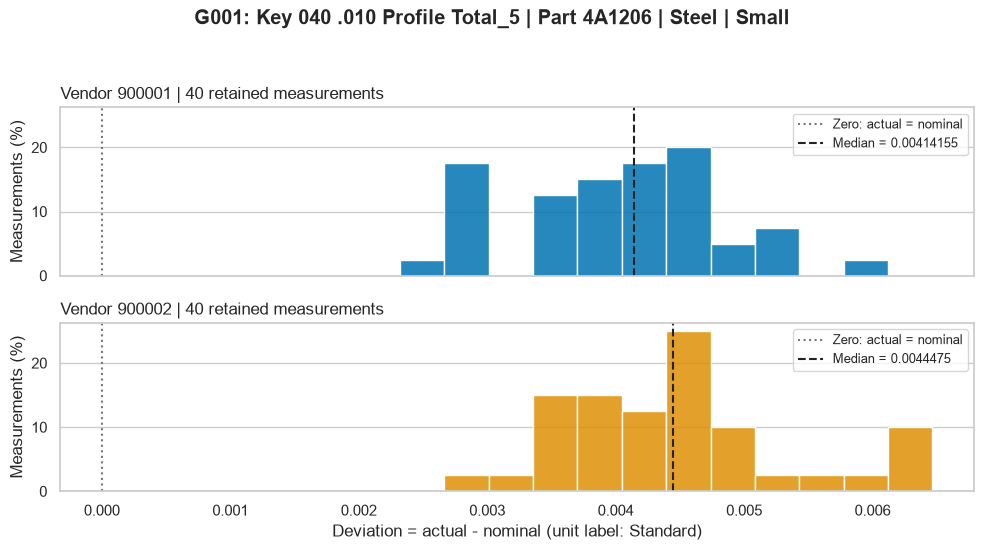

Read within this context: compare medians, spread, and tails; each vendor panel totals 100%.

Check the date ranges before attributing a difference to the vendor. No significance or pass/fail test is performed.

In [23]:
# Purpose: Compare calculated deviations across vendors within the selected context.
vc_vendor_summary = pd.DataFrame()
if vc_selected_id is not None:
    vc_vendor_summary = vc_selected.groupby("vendor_id").agg(
        measurements=("calculated_deviation", "size"),
        assumed_unit_records=("unit_assumed_standard", "sum"),
        mean=("calculated_deviation", "mean"), median=("calculated_deviation", "median"),
        std=("calculated_deviation", "std"), minimum=("calculated_deviation", "min"),
        maximum=("calculated_deviation", "max"), dated_records=("date", "count"),
        first_date=("date", "min"), last_date=("date", "max")).reset_index()
    print("Calculated deviation summary: retained records from qualifying vendors only.")
    display(vc_vendor_summary)
    if "vendor_name" in vc_selected:
        display(vc_selected[["vendor_id", "vendor_name"]].drop_duplicates())
    if P2_PLOTS:
        vc_bins = np.histogram_bin_edges(vc_selected.calculated_deviation, bins=12)
        vc_vendors = vc_vendor_summary.vendor_id.tolist()
        fig, axes = plt.subplots(len(vc_vendors), 1, figsize=(10, 2.8 * len(vc_vendors)),
                                 sharex=True, sharey=True, squeeze=False)
        for ax, vendor, color in zip(axes.flat, vc_vendors, sns.color_palette("colorblind", len(vc_vendors))):
            values = vc_selected.loc[vc_selected.vendor_id.eq(vendor), "calculated_deviation"]
            sns.histplot(x=values, bins=vc_bins, stat="percent", color=color,
                         edgecolor="white", alpha=0.85, ax=ax)
            ax.axvline(0, color="#777777", linestyle=":", label="Zero: actual = nominal")
            ax.axvline(values.median(), color="#222222", linestyle="--",
                       label=f"Median = {values.median():.6g}")
            ax.set_title(f"Vendor {vendor} | {len(values):,} retained measurements", loc="left")
            ax.set_ylabel("Measurements (%)")
            ax.grid(axis="x", visible=False)
            ax.ticklabel_format(axis="x", style="plain", useOffset=False)
            ax.legend(fontsize=9)
        vc_context = vc_lookup.loc[vc_lookup.comparison_id.eq(vc_selected_id)].iloc[0]
        axes[-1, 0].set_xlabel(f"Deviation = actual - nominal (unit label: {vc_context['unit']})")
        from textwrap import fill
        fig.suptitle(fill(f"{vc_selected_id}: {vc_context['feature_name']} | Part {vc_context['part_number']} | "
                         f"{vc_context['material_family']} | {vc_context['size']}", 85), fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show(); plt.close()
    print("Read within this context: compare medians, spread, and tails; each vendor panel totals 100%.")
    print("Check the date ranges before attributing a difference to the vendor. No significance or pass/fail test is performed.")


### Save only the four main review files

| File | Contents |
|---|---|
| `exact_duplicate_evidence.csv` | Original members of exact-match sets, with removal/inclusion decisions. Audit only. |
| `missing_context_records.csv` | Original rows with missing size or remaining missing context after unit filling, with cleaning decisions. Audit only. |
| `group_before_after.csv` | Before-removal and cleaned statistics within retained eligible contexts. |
| `iqr_flagged_records.csv` | Review flags from eligible cleaned records only. |

Exactly four Part II files are refreshed when `EXPORT_TABLES=True`. Part I's four analysis summaries remain separate and now also use cleaned data. Empty tables retain column headers; previews never truncate the exports. Source-audit files deliberately retain evidence of removed rows, while analysis files exclude those rows. The original CSV is never overwritten.


In [24]:
# Purpose: Write exactly four review tables; keep other summaries in the notebook.
part_ii_exports = {
    "exact_duplicate_evidence.csv": p2_duplicate_evidence,
    "missing_context_records.csv": p2_context_records,
    "group_before_after.csv": p2_changes,
    "iqr_flagged_records.csv": p2_flagged,
}
if EXPORT_TABLES:
    PART_II_FOLDER.mkdir(parents=True, exist_ok=True)
    for p2_filename, p2_table in part_ii_exports.items():
        p2_target = PART_II_FOLDER / p2_filename
        if p2_target.resolve() == CSV_PATH.resolve():
            raise ValueError("Choose an output folder that does not overwrite the source CSV.")
        p2_table.to_csv(p2_target, index=False)
        print(f"{p2_filename}: {len(p2_table):,} rows saved")
    print("Part II folder:", PART_II_FOLDER.resolve())
else:
    print("Exports disabled; the four complete tables remain available in part_ii_exports.")


exact_duplicate_evidence.csv: 4 rows saved

missing_context_records.csv: 0 rows saved

group_before_after.csv: 2 rows saved

iqr_flagged_records.csv: 7 rows saved

Part II folder:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\initial_eda_summaries\part_ii

### Vendor overlays: detail and full-range histogram

The histogram uses common intervals chosen from the pooled deviations, with between 12 and 60 bins. Transparent fills and different line styles distinguish vendors. The left panel focuses on the pooled 1st–99th percentile range; the right shows the complete range. Both panels use the same bins and percentage scale. No rows are filtered for zooming, and percentages always use each vendor's complete selected sample. The table reports how many measurements lie outside the detail view for each vendor. These limits are display choices, not outlier thresholds. For constant or heavily tied values with identical percentile bounds, the detail panel uses the full range.

The KDE below is a separate smooth estimate, with 18% opacity fills and solid outlines so overlapping vendor curves remain visible. Increase `alpha` for darker fill or lower it for lighter fill. Its density axis is different from the histogram's percentage axis. Compare shape and location, not heights between these two plot types.


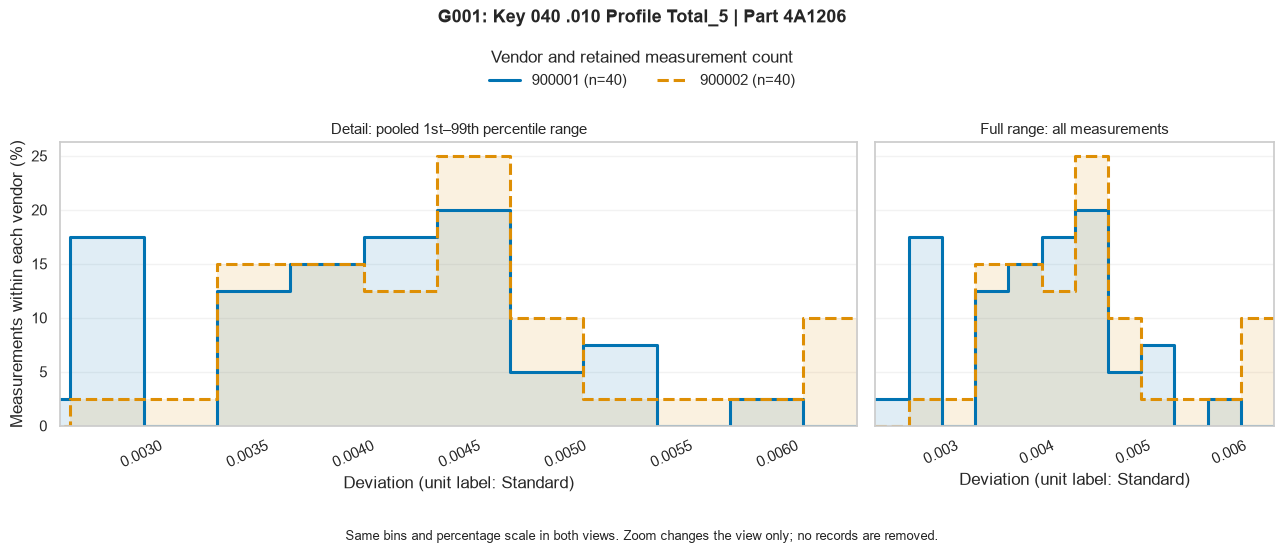

Shared histogram intervals: 12. Detail limits: 0.0026174 to 0.00637657.

Each vendor totals 100% over the FULL range; the detail view is not renormalized.

Measurements outside the detail view remain in the full-range chart and all calculations:

,measurements,outside_detail
vendor_id,,
900001,40,1
900002,40,1


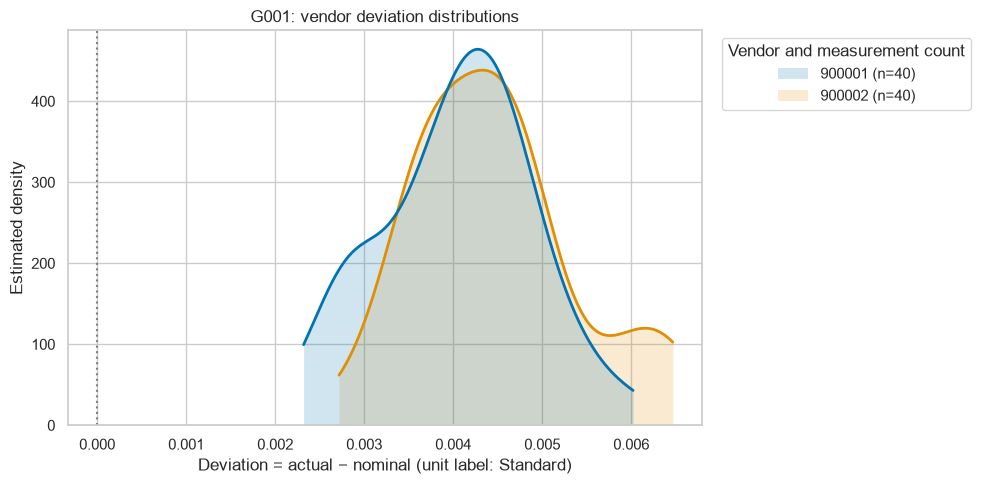

In [25]:
# Overlay histogram: readable detail plus the complete measurement range.
plot_data = vc_selected.copy()
plot_data = plot_data.dropna(subset=["calculated_deviation", "vendor_id"])
OVERLAY_MAX_BINS = 60
overlay_counts = pd.DataFrame()

if not P2_PLOTS:
    print("Vendor overlay histogram disabled by P2_PLOTS.")
elif plot_data.vendor_id.nunique() < 2:
    print("Overlay histogram needs at least two vendors with usable measurements.")
else:
    values_all = plot_data.calculated_deviation.to_numpy()
    # Choose common intervals from the pooled data, with a limit on tiny bins.
    suggested_bins = len(np.histogram_bin_edges(values_all, bins="fd")) - 1
    bin_count = max(12, min(OVERLAY_MAX_BINS, suggested_bins))
    overlay_bins = np.histogram_bin_edges(values_all, bins=bin_count)
    focus_low, focus_high = np.quantile(values_all, [0.01, 0.99])
    if focus_low == focus_high:
        focus_low, focus_high = overlay_bins[0], overlay_bins[-1]
        focus_title = "Detail view: no distinct central range"
    else:
        focus_title = "Detail: pooled 1st–99th percentile range"

    overlay_counts = plot_data.groupby("vendor_id", sort=False).agg(
        measurements=("calculated_deviation", "size"))
    plot_data["outside_detail"] = (plot_data.calculated_deviation.lt(focus_low)
                                  | plot_data.calculated_deviation.gt(focus_high))
    overlay_counts["outside_detail"] = plot_data.groupby("vendor_id").outside_detail.sum()
    vendors = overlay_counts.index.tolist()
    colors = sns.color_palette("colorblind", len(vendors))
    line_styles = ["-", "--", "-.", ":"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True,
                             gridspec_kw={"width_ratios": [2, 1]})
    for i, (vendor, color) in enumerate(zip(vendors, colors)):
        values = plot_data.loc[plot_data.vendor_id.eq(vendor), "calculated_deviation"]
        label = f"{vendor} (n={len(values):,})"
        for ax in axes:
            # Both calls use ALL of this vendor's values, including those outside the zoom.
            sns.histplot(x=values, bins=overlay_bins, stat="percent", element="step",
                         fill=True, color=color, alpha=0.12, linewidth=0, ax=ax)
            sns.histplot(x=values, bins=overlay_bins, stat="percent", element="step",
                         fill=False, color=color, linewidth=2.2,
                         linestyle=line_styles[i % len(line_styles)], label=label, ax=ax)

    axes[0].set_xlim(focus_low, focus_high)
    axes[0].set_title(focus_title, fontsize=11)
    axes[1].set_xlim(overlay_bins[0], overlay_bins[-1])
    axes[1].set_title("Full range: all measurements", fontsize=11)
    unit_label = plot_data.unit.iloc[0]
    for ax in axes:
        lo, hi = ax.get_xlim()
        if lo <= 0 <= hi:
            ax.axvline(0, color="#777777", linestyle=":", linewidth=1)
        ax.set_xlabel(f"Deviation (unit label: {unit_label})")
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
        ax.tick_params(axis="x", rotation=25)
        ax.grid(axis="x", visible=False)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Measurements within each vendor (%)")
    axes[1].set_ylabel("")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Vendor and retained measurement count",
               loc="upper center", bbox_to_anchor=(0.5, 0.93),
               ncol=min(3, len(vendors)), frameon=False)
    from textwrap import fill
    context = plot_data.iloc[0]
    fig.suptitle(fill(f"{vc_selected_id}: {context['feature_name']} | Part {context['part_number']}", 95),
                 fontsize=13, fontweight="bold")
    fig.text(0.5, 0.015,
             "Same bins and percentage scale in both views. Zoom changes the view only; no records are removed.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=[0, 0.07, 1, 0.87])
    plt.show(); plt.close(fig)
    print(f"Shared histogram intervals: {bin_count}. Detail limits: {focus_low:.6g} to {focus_high:.6g}.")
    print("Each vendor totals 100% over the FULL range; the detail view is not renormalized.")
    print("Measurements outside the detail view remain in the full-range chart and all calculations:")
    display(overlay_counts)

# KDE overlay for vendors in the selected comparison group.
kde_data = vc_selected.dropna(
    subset=["calculated_deviation", "vendor_id"]
).copy()

# KDE requires variation; keep the existing minimum sample rule.
vendor_checks = kde_data.groupby("vendor_id").agg(
    measurements=("calculated_deviation", "size"),
    distinct_values=("calculated_deviation", "nunique")
)

eligible_vendors = vendor_checks.index[
    (vendor_checks["measurements"] >= MIN_VENDOR_MEASUREMENTS)
    & (vendor_checks["distinct_values"] > 1)
]

skipped = vendor_checks.loc[
    ~vendor_checks.index.isin(eligible_vendors)
]
if not skipped.empty:
    print("Vendors skipped: too few measurements or no variation.")
    display(skipped)

kde_data = kde_data[
    kde_data["vendor_id"].isin(eligible_vendors)
].copy()

if kde_data["vendor_id"].nunique() < 2:
    print("KDE comparison needs at least two eligible vendors.")
else:
    kde_data["vendor_label"] = kde_data["vendor_id"].map(
        lambda vendor:
            f"{vendor} (n={vendor_checks.loc[vendor, 'measurements']:,})"
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    sns.kdeplot(
        data=kde_data,
        x="calculated_deviation",
        hue="vendor_label",
        common_norm=False,   # Normalize each vendor independently.
        bw_adjust=1,         # Larger = smoother; smaller = more detail.
        cut=0,               # Stop each curve at its observed limits.
        fill=True,
        alpha=0.18,          # Transparent fill keeps overlapping vendors visible.
        linewidth=0,
        palette="colorblind",
        ax=ax
    )
    # Redraw solid outlines above the transparent fills with identical KDE settings.
    sns.kdeplot(
        data=kde_data,
        x="calculated_deviation",
        hue="vendor_label",
        common_norm=False,
        bw_adjust=1,
        cut=0,
        fill=False,
        linewidth=2,
        palette="colorblind",
        legend=False,
        ax=ax
    )

    ax.axvline(0, color="gray", linestyle=":", linewidth=1.5)

    unit_label = kde_data["unit"].iloc[0]
    ax.set_xlabel(
        f"Deviation = actual − nominal (unit label: {unit_label})"
    )
    ax.set_ylabel("Estimated density")
    ax.set_title(f"{vc_selected_id}: vendor deviation distributions")

    sns.move_legend(
        ax, "upper left",
        bbox_to_anchor=(1.02, 1),
        title="Vendor and measurement count"
    )

    plt.tight_layout()
    plt.show()

## 7. Parallelism: compare vendors across shared measurement groups

**Purpose:** Review all eligible parallelism groups together, then summarize vendor pairs using only groups they share. This section is independent of `FIRST_COMPARISON_ID` and the single-group plot selection above.

**Approved assumptions:** The same unit labels and parallelism definitions have the same physical meaning across vendors. Empty units are already filled with Standard. For nonnegative parallelism with nominal 0, lower tolerance 0, and positive upper tolerance, treat the upper tolerance as the maximum permitted measurement. Standard and Metric remain separate unit categories; no conversion is performed. Other legitimate specifications remain separate groups and are listed if this particular normalization does not apply.

**7.1 Coverage and metrics:** Each group must contain at least two vendors with `MIN_VENDOR_MEASUREMENTS` usable records each (currently 10). The count table also shows vendors below that threshold; blanks mean no usable records in that group. Metrics use only qualifying vendors. All counts follow the approved duplicate removal and missing-size exclusion. A measurement count is not necessarily a count of independent parts.

The median absolute deviation **from nominal** is `median(abs(actual - nominal))`, not the different statistic called median absolute deviation from the sample median. IQR is Q3 minus Q1 of signed deviations; P95 is the 95th percentile of absolute deviations. Dates show coverage, not continuous inspection. Missing dates remain counted and do not remove otherwise usable measurements.

**7.2 Heatmap:** For eligible one-sided parallelism, `actual / upper_tolerance * 100` measures percentage of the upper limit. For example, 0.0004 / 0.001 = 40%. Each cell shows the median of those percentages and the vendor's count. Lower percentages indicate smaller typical measurements relative to the limit. This is not a failure percentage. Blank cells mean absent, insufficient, or ineligible data, never zero performance. All pages share one color scale; full tables remain available even when previews are shorter.

**7.3 Shared-group summary:** For each vendor pair within a unit label, average each vendor's group medians over exactly the same shared groups, with equal weight per group. This describes those shared features; it is not an overall vendor ranking. A one-group comparison is labeled as such. Date-range overlap is only a preliminary coverage check: it does not match batches, inspection methods, or individual dates. Use Section 6 and the existing time plots to investigate specific groups before attributing differences to vendors. No new CSV exports are added.

In [26]:
# 7.1: Use all eligible cleaned parallelism records, regardless of the selected chart group.
parallelism_records = vc_data.loc[
    vc_data.feature_type.str.strip().str.casefold().eq("parallelism").fillna(False)
].copy()
parallelism_counts = parallelism_records.groupby(["comparison_id", "vendor_id"]).size().rename("measurements").reset_index()
parallelism_qualified = parallelism_counts.loc[parallelism_counts.measurements >= MIN_VENDOR_MEASUREMENTS].copy()
parallelism_group_ids = parallelism_qualified.groupby("comparison_id").size()
parallelism_group_ids = parallelism_group_ids.loc[parallelism_group_ids >= 2].index
parallelism_context = vc_lookup.loc[vc_lookup.comparison_id.isin(parallelism_group_ids)].copy()
parallelism_qualified = parallelism_qualified.loc[parallelism_qualified.comparison_id.isin(parallelism_group_ids)]

parallelism_coverage = parallelism_counts.loc[
    parallelism_counts.comparison_id.isin(parallelism_group_ids)
].pivot(index="comparison_id", columns="vendor_id", values="measurements").astype("Int64")
parallelism_coverage_table = parallelism_context.set_index("comparison_id").join(parallelism_coverage)
print(f"Eligible parallelism comparison groups: {len(parallelism_context):,}")
print(f"Coverage: counts below {MIN_VENDOR_MEASUREMENTS} remain visible but are excluded from metrics and charts; blanks mean no usable records.")
display(parallelism_coverage_table.head(TABLE_PREVIEW_ROWS))

parallelism_measured = parallelism_records.merge(
    parallelism_qualified[["comparison_id", "vendor_id"]],
    on=["comparison_id", "vendor_id"], how="inner", validate="many_to_one")
parallelism_measured["absolute_deviation"] = parallelism_measured.calculated_deviation.abs()
parallelism_metrics = parallelism_measured.groupby(["comparison_id", "vendor_id"]).agg(
    measurements=("actual", "size"),
    median_deviation=("calculated_deviation", "median"),
    median_absolute_deviation_from_nominal=("absolute_deviation", "median"),
    iqr_deviation=("calculated_deviation", lambda values: values.quantile(.75) - values.quantile(.25)),
    p95_absolute_deviation=("absolute_deviation", lambda values: values.quantile(.95)),
    first_date=("date", "min"), last_date=("date", "max"),
    missing_dates=("date", lambda values: int(values.isna().sum())),
    assumed_standard_records=("unit_assumed_standard", "sum"),
).reset_index().merge(parallelism_context, on="comparison_id", validate="many_to_one")

# A negative actual in any eligible-context record blocks normalization for that entire group.
parallelism_minimum = parallelism_records.groupby("comparison_id").actual.min()
parallelism_normalization = parallelism_context.copy()
parallelism_normalization["minimum_actual"] = parallelism_normalization.comparison_id.map(parallelism_minimum)
parallelism_normalization["normalization_status"] = np.select(
    [parallelism_normalization.nominal.ne(0),
     parallelism_normalization.lower_tolerance.ne(0),
     parallelism_normalization.upper_tolerance.le(0),
     parallelism_normalization.minimum_actual.lt(0)],
    ["not normalized: nominal is not zero", "not normalized: lower tolerance is not zero",
     "not normalized: upper limit is not positive", "not normalized: negative actual values"],
    default="ready")
parallelism_metrics = parallelism_metrics.merge(
    parallelism_normalization[["comparison_id", "normalization_status"]],
    on="comparison_id", validate="many_to_one")
parallelism_metrics["median_upper_limit_percent"] = np.nan
parallelism_normalized = parallelism_metrics.normalization_status.eq("ready")
parallelism_metrics.loc[parallelism_normalized, "median_upper_limit_percent"] = (
    100 * parallelism_metrics.loc[parallelism_normalized, "median_absolute_deviation_from_nominal"]
    / parallelism_metrics.loc[parallelism_normalized, "upper_tolerance"])
display(parallelism_metrics.head(TABLE_PREVIEW_ROWS))
print("Full tables: parallelism_coverage_table and parallelism_metrics. No new exports.")
parallelism_not_normalized = parallelism_normalization.loc[parallelism_normalization.normalization_status.ne("ready")]
print(f"Groups excluded from percentage-of-limit heatmap: {len(parallelism_not_normalized):,}")
if not parallelism_not_normalized.empty:
    display(parallelism_not_normalized)
if parallelism_context.empty:
    print("No parallelism groups meet the two-vendor minimum in this input. The synthetic example has no parallelism records.")

Eligible parallelism comparison groups: 0

Coverage: counts below 10 remain visible but are excluded from metrics and charts; blanks mean no usable records.

,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
comparison_id,,,,,,,,,


,comparison_id,vendor_id,measurements,median_deviation,median_absolute_deviation_from_nominal,iqr_deviation,p95_absolute_deviation,first_date,last_date,missing_dates,assumed_standard_records,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,normalization_status,median_upper_limit_percent


Full tables: parallelism_coverage_table and parallelism_metrics. No new exports.

Groups excluded from percentage-of-limit heatmap: 0

No parallelism groups meet the two-vendor minimum in this input. The synthetic example has no parallelism records.

In [27]:
# 7.2: One row per measurement group, with full context labels and a common color scale.
parallelism_heatmap_data = parallelism_metrics.loc[parallelism_normalized].copy()
parallelism_heatmap = parallelism_heatmap_data.pivot(
    index="comparison_id", columns="vendor_id", values="median_upper_limit_percent")
parallelism_heatmap_counts = parallelism_heatmap_data.pivot(
    index="comparison_id", columns="vendor_id", values="measurements")
if P2_PLOTS and not parallelism_heatmap.empty:
    parallelism_labels = parallelism_context.set_index("comparison_id")
    parallelism_scale_max = max(100.0, float(parallelism_heatmap.max().max()))
    for start in range(0, len(parallelism_heatmap), 15):
        panel = parallelism_heatmap.iloc[start:start + 15]
        annotations = pd.DataFrame("", index=panel.index, columns=panel.columns)
        for gid in panel.index:
            for vendor in panel.columns:
                if pd.notna(panel.loc[gid, vendor]):
                    annotations.loc[gid, vendor] = f"{panel.loc[gid, vendor]:.1f}%\nn={int(parallelism_heatmap_counts.loc[gid, vendor]):,}"
        labels = []
        for gid in panel.index:
            context = parallelism_labels.loc[gid]
            labels.append(f"{gid} | {context.feature_name} | Part {context.part_number}\n"
                          f"{context.material_family}, {context['size']}, {context.unit} | upper={context.upper_tolerance:g}")
        fig, ax = plt.subplots(figsize=(max(9, 1.35 * len(panel.columns)), max(3, .85 * len(panel))))
        ax.set_facecolor("#eeeeee")
        sns.heatmap(panel.astype(float), mask=panel.isna(), annot=annotations, fmt="",
                    cmap="YlOrRd", vmin=0, vmax=parallelism_scale_max, linewidths=.5,
                    cbar_kws={"label": "Median measurement as % of upper limit"}, ax=ax)
        ax.set_yticklabels(labels, rotation=0)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
        ax.set(xlabel="Vendor ID", ylabel="Comparison group",
               title=f"Parallelism: typical measurement relative to upper limit ({start + 1}–{start + len(panel)} of {len(parallelism_heatmap)})")
        fig.text(.5, .01, "Gray = no qualifying value. Counts follow cleaning. Percentages are not failure rates.", ha="center", fontsize=9)
        fig.tight_layout(rect=[0, .05, 1, 1])
        plt.show(); plt.close(fig)
elif parallelism_heatmap.empty:
    print("Parallelism heatmap skipped: no qualifying groups support percentage-of-limit comparison.")

Parallelism heatmap skipped: no qualifying groups support percentage-of-limit comparison.

In [28]:
# 7.3: Summarize only identical shared group sets within each vendor pair and unit label.
from itertools import combinations
parallelism_pair_rows = []
for unit_label, unit_metrics in parallelism_heatmap_data.groupby("unit", sort=True):
    for vendor_a, vendor_b in combinations(sorted(unit_metrics.vendor_id.unique()), 2):
        a = unit_metrics.loc[unit_metrics.vendor_id.eq(vendor_a)].set_index("comparison_id")
        b = unit_metrics.loc[unit_metrics.vendor_id.eq(vendor_b)].set_index("comparison_id")
        shared = sorted(set(a.index) & set(b.index))
        if not shared:
            continue
        a, b = a.loc[shared], b.loc[shared]
        dates_complete = a.first_date.notna() & a.last_date.notna() & b.first_date.notna() & b.last_date.notna()
        overlaps = dates_complete & a.first_date.le(b.last_date) & b.first_date.le(a.last_date)
        value_a, value_b = a.median_upper_limit_percent.mean(), b.median_upper_limit_percent.mean()
        parallelism_pair_rows.append(dict(
            unit=unit_label, vendor_a=vendor_a, vendor_b=vendor_b, shared_groups=len(shared),
            comparison_ids=", ".join(shared), measurements_a=int(a.measurements.sum()),
            measurements_b=int(b.measurements.sum()),
            mean_group_median_percent_a=value_a, mean_group_median_percent_b=value_b,
            difference_b_minus_a_percentage_points=value_b - value_a,
            groups_with_overlapping_date_ranges=int(overlaps.sum()),
            groups_without_date_range_overlap=int((dates_complete & ~overlaps).sum()),
            groups_with_unknown_date_ranges=int((~dates_complete).sum()),
            scope="one group only" if len(shared) == 1 else "equal weight across the same shared groups"))
parallelism_pair_summary = pd.DataFrame(parallelism_pair_rows, columns=[
    "unit", "vendor_a", "vendor_b", "shared_groups", "comparison_ids", "measurements_a", "measurements_b",
    "mean_group_median_percent_a", "mean_group_median_percent_b", "difference_b_minus_a_percentage_points",
    "groups_with_overlapping_date_ranges", "groups_without_date_range_overlap", "groups_with_unknown_date_ranges", "scope"])
print("Shared-group vendor comparisons: each group's median has equal weight, regardless of measurement count.")
display(parallelism_pair_summary)
print("A positive difference means vendor B's typical percentage is higher across these shared groups. It is not a significance test.")
print("Date-range overlap does not establish matched inspection dates or batches. Different pair rows may cover different groups; do not use them as an overall ranking.")

Shared-group vendor comparisons: each group's median has equal weight, regardless of measurement count.

,unit,vendor_a,vendor_b,shared_groups,comparison_ids,measurements_a,measurements_b,mean_group_median_percent_a,mean_group_median_percent_b,difference_b_minus_a_percentage_points,groups_with_overlapping_date_ranges,groups_without_date_range_overlap,groups_with_unknown_date_ranges,scope


A positive difference means vendor B's typical percentage is higher across these shared groups. It is not a significance test.

Date-range overlap does not establish matched inspection dates or batches. Different pair rows may cover different groups; do not use them as an overall ranking.

### 7.4 Vendor boxplots and KDEs for every eligible parallelism group

Each figure compares vendors **within one comparison ID**, using the same cleaned, qualifying measurements as Section 7.1. All eligible groups are plotted; the single-group selection and table preview limit do not restrict these figures. Vendor colors stay consistent across this section. Each legend and boxplot label includes the measurement count.

**Left: boxplot.** The middle line is the median; the box contains the middle 50% of deviations (Q1 to Q3). Whiskers extend to the most extreme observations within 1.5 IQR of the box. Points beyond the whiskers remain visible; they are statistical outliers, not automatically errors or specification failures.

**Right: transparent KDE overlay.** Each vendor's curve is independently normalized to estimate its distribution. The vertical axis is density, not count or percentage; taller peaks indicate concentration. Filled areas use 18% opacity with solid/dashed outlines so overlaps remain visible. Smoothing may obscure details, so read it alongside the boxplot. A vendor with no variation has no estimable KDE; its constant value is shown as a labeled vertical line and remains in the boxplot.

Both panels use the same full deviation range within that group, without trimming extremes. Zero is shown as a dotted reference for actual = nominal. These axes retain the group's source unit label; they are not the heatmap's percentage-of-limit scale. `cut=0` limits each KDE to its observed range but does not correct boundary bias. Use the date coverage in Section 7.1 when interpreting differences; these plots do not establish vendor causation or process stability. Set `P2_PLOTS=False` to disable the figures. No extra CSV exports are created.


In [29]:
# 7.4: Boxplot and transparent KDE for every eligible parallelism comparison.
from matplotlib.lines import Line2D
from textwrap import fill

parallelism_plot_vendors = sorted(parallelism_measured.vendor_id.unique())
parallelism_vendor_colors = dict(zip(
    parallelism_plot_vendors, sns.color_palette("colorblind", n_colors=len(parallelism_plot_vendors))))
parallelism_vendor_styles = {vendor: ["-", "--", "-.", ":"][i % 4]
                             for i, vendor in enumerate(parallelism_plot_vendors)}
parallelism_plot_groups = sorted(parallelism_measured.comparison_id.unique())
if not P2_PLOTS:
    print("Parallelism boxplots and KDEs disabled by P2_PLOTS.")
elif not parallelism_plot_groups:
    print("Parallelism boxplots and KDEs skipped: no groups meet the vendor-count requirements.")
else:
    print(f"Plotting {len(parallelism_plot_groups):,} parallelism groups: one boxplot and KDE panel per group.")
    for gid in parallelism_plot_groups:
        current = parallelism_measured.loc[parallelism_measured.comparison_id.eq(gid)].copy()
        context = parallelism_context.loc[parallelism_context.comparison_id.eq(gid)].iloc[0]
        vendors = sorted(current.vendor_id.unique())
        counts = current.groupby("vendor_id").size()
        fig, (box_ax, kde_ax) = plt.subplots(1, 2, figsize=(14, max(5.2, .55 * len(vendors) + 3)), sharex=True)
        sns.boxplot(data=current, x="calculated_deviation", y="vendor_id", hue="vendor_id",
                    order=vendors, hue_order=vendors, palette=parallelism_vendor_colors,
                    dodge=False, legend=False, width=.5, whis=1.5, showfliers=True,
                    flierprops={"marker": "o", "markersize": 3, "alpha": .45}, ax=box_ax)
        box_ax.set_yticks(range(len(vendors)), [f"{v} (n={counts[v]:,})" for v in vendors])
        box_ax.set(title="Median, middle 50%, and unusual values", ylabel="Vendor ID and measurement count")
        handles, constant_vendors = [], []
        for vendor in vendors:
            values = current.loc[current.vendor_id.eq(vendor), "calculated_deviation"]
            color, style = parallelism_vendor_colors[vendor], parallelism_vendor_styles[vendor]
            label = f"{vendor} (n={len(values):,})"
            if values.nunique() < 2 or values.std() == 0:
                kde_ax.axvline(float(values.iloc[0]), color=color, linestyle=style, linewidth=2)
                label += " - constant; no KDE"
                constant_vendors.append(str(vendor))
            else:
                sns.kdeplot(x=values, fill=True, alpha=.18, linewidth=0, color=color,
                            common_norm=False, bw_adjust=1, cut=0, ax=kde_ax)
                sns.kdeplot(x=values, fill=False, linewidth=2, color=color, linestyle=style,
                            common_norm=False, bw_adjust=1, cut=0, ax=kde_ax)
            handles.append(Line2D([0], [0], color=color, linestyle=style, linewidth=2, label=label))
        kde_ax.set(title="Distribution shape by vendor", ylabel="Estimated density (not percent)")
        if len(constant_vendors) == len(vendors):
            kde_ax.set(yticks=[], ylabel="Constant measurements (no density estimate)")
        kde_ax.legend(handles=handles, title="Vendor ID and measurement count", fontsize=9)
        # Preserve the full observed range and zero; do not crop or remove tail measurements.
        low = min(0., float(current.calculated_deviation.min()))
        high = max(0., float(current.calculated_deviation.max()))
        padding = .04 * (high - low) if high > low else .000001
        box_ax.set_xlim(low - padding, high + padding)
        for ax in (box_ax, kde_ax):
            ax.axvline(0, color="gray", linestyle=":", linewidth=1.2, zorder=0)
            ax.set_xlabel(f"Deviation = actual - nominal (unit label: {context.unit})")
            ax.ticklabel_format(axis="x", style="plain", useOffset=False)
            ax.tick_params(axis="x", labelrotation=25)
            ax.grid(axis="x", alpha=.2)
            ax.set_axisbelow(True)
        title = fill(f"{gid}: {context.feature_name} | Part {context.part_number}", 100)
        detail = (f"{context.material_family} | {context['size']} | {context.unit} | "
                  f"nominal={context.nominal:g}, upper tolerance={context.upper_tolerance:g}, lower tolerance={context.lower_tolerance:g}")
        fig.suptitle(title + "\n" + fill(detail, 110), fontsize=12)
        note = "Dotted line = zero deviation. Full measurement range shown. Boxplot outliers are not failure counts."
        if constant_vendors:
            note += "\nConstant values shown as lines instead of KDEs: " + ", ".join(constant_vendors)
            print(f"{gid}: KDE unavailable for constant-value vendors: {', '.join(constant_vendors)}; boxplots retain their measurements.")
        fig.text(.5, .015, note, ha="center", fontsize=9)
        fig.tight_layout(rect=[0, .10, 1, .96])
        plt.show(); plt.close(fig)


Parallelism boxplots and KDEs skipped: no groups meet the vendor-count requirements.

## 8. Broader parallelism comparisons across parts

**Question:** What do each vendor's parallelism measurements look like across the parts and features it supplies, under the same recorded requirements?

We now allow **different part numbers and feature names**, using the approved assumption that these parallelism measurements have compatible physical meanings. We retain exact matching on **feature type, material, size, unit, nominal, upper tolerance, and lower tolerance**. This broadens coverage while controlling several known differences in requirements. It does not make different geometries, batches, dates, or inspection methods equivalent. Standard and Metric are separate; no conversion, tolerance rounding, or tolerance bands are introduced.

This section starts from **all eligible cleaned parallelism records in `vc_data`**, including features with only one vendor. It does not filter to Section 7's shared groups. Exact copies and missing-size rows are already removed, blank units already mean Standard, and deviation is actual minus nominal. Missing comparison fields, unusable measurements, and missing vendor IDs remain excluded by the existing eligibility checks.

Broad IDs (`B001`, etc.) identify these new contexts; original `G...` IDs still identify individual measurement groups. Both IDs are generated for this input, not supplied in the CSV. Group counts are discovered dynamically, not taken from screenshots. The original CSV and detailed comparisons remain intact.

### 8.1 Coverage, part mix, and pooled metrics

Require at least **10 usable measurements per vendor in a broad context**, using `MIN_VENDOR_MEASUREMENTS`, and at least two qualifying vendors per comparison. A vendor can reach 10 across several small features: this is a screening rule, not proof of independence or adequate evidence for every part.

The inventory shows all broad contexts and whether they qualify. Coverage and vendor-by-part tables retain below-threshold vendors and mark them; plots and summaries use qualifying vendors only. Missing cells mean no eligible records, not zero deviation. `record_share_percent` shows how much of a vendor's broad-context data comes from each part. Vendor metrics include measurement, part, and feature-group counts, median deviations, IQR, P95, date coverage, and unit-assumption counts. These pooled metrics give every retained measurement equal weight, so frequently inspected features contribute more.

Table previews respect `TABLE_PREVIEW_ROWS`; the complete tables remain in the named DataFrames. All new results stay inside the notebook, with no additional CSV exports.

In [30]:
# 8.1: Broaden part/feature matching, retaining all other comparison requirements.
BROAD_KEYS = ["feature_type", "material_family", "size", "unit", "nominal", "upper_tolerance", "lower_tolerance"]
broad_records = vc_data.loc[vc_data.feature_type.str.strip().str.casefold().eq("parallelism").fillna(False)].copy()
broad_records["broad_id"] = (broad_records.groupby(BROAD_KEYS, sort=True, dropna=False).ngroup()
                              .map(lambda number: f"B{int(number)+1:03d}"))
broad_lookup = broad_records[["broad_id"] + BROAD_KEYS].drop_duplicates()
broad_counts = broad_records.groupby(["broad_id", "vendor_id"]).size().rename("measurements").reset_index()
broad_counts["vendor_meets_minimum"] = broad_counts.measurements >= MIN_VENDOR_MEASUREMENTS
broad_qualifying_counts = broad_counts.loc[broad_counts.vendor_meets_minimum].groupby("broad_id").size()
broad_inventory = broad_records.groupby("broad_id").agg(
    measurements=("actual", "size"), vendors=("vendor_id", "nunique"),
    parts=("part_number", "nunique"), feature_groups=("comparison_id", "nunique")
).reset_index().merge(broad_lookup, on="broad_id", validate="one_to_one")
broad_inventory["qualifying_vendors"] = broad_inventory.broad_id.map(broad_qualifying_counts).fillna(0).astype(int)
broad_inventory["comparison_available"] = broad_inventory.qualifying_vendors >= 2
broad_ids = broad_inventory.loc[broad_inventory.comparison_available, "broad_id"]
broad_candidates = broad_inventory.loc[broad_inventory.comparison_available].copy()
broad_counts["included_in_comparison"] = broad_counts.vendor_meets_minimum & broad_counts.broad_id.isin(broad_ids)
broad_measured = broad_records.merge(
    broad_counts.loc[broad_counts.included_in_comparison, ["broad_id", "vendor_id"]],
    on=["broad_id", "vendor_id"], how="inner", validate="many_to_one")
broad_measured["absolute_deviation"] = broad_measured.calculated_deviation.abs()

print(f"Eligible cleaned parallelism records before broad vendor-count screening: {len(broad_records):,}")
print(f"Broad contexts: {len(broad_inventory):,}; contexts with at least two qualifying vendors: {len(broad_candidates):,}")
print(f"Records included in broad comparisons: {len(broad_measured):,}; omitted by vendor/context count rules: {len(broad_records)-len(broad_measured):,}")
display(broad_inventory.head(TABLE_PREVIEW_ROWS))
broad_coverage = broad_counts.loc[broad_counts.broad_id.isin(broad_ids)].pivot(
    index="broad_id", columns="vendor_id", values="measurements").astype("Int64")
display(broad_candidates.set_index("broad_id")[BROAD_KEYS].join(broad_coverage).head(TABLE_PREVIEW_ROWS))
print(f"Coverage counts below {MIN_VENDOR_MEASUREMENTS} remain visible but are not plotted.")

broad_part_mix = broad_records.loc[broad_records.broad_id.isin(broad_ids)].groupby(
    ["broad_id", "vendor_id", "part_number"]).agg(
        measurements=("actual", "size"), feature_groups=("comparison_id", "nunique")
).reset_index().merge(broad_counts[["broad_id", "vendor_id", "included_in_comparison"]],
                     on=["broad_id", "vendor_id"], validate="many_to_one")
broad_part_mix["record_share_percent"] = 100 * broad_part_mix.measurements / broad_part_mix.groupby(
    ["broad_id", "vendor_id"]).measurements.transform("sum")
broad_part_coverage = broad_part_mix.pivot(index=["broad_id", "part_number"], columns="vendor_id", values="measurements").astype("Int64")
print("Vendor-by-part measurement counts (including below-threshold vendors):")
display(broad_part_coverage.head(TABLE_PREVIEW_ROWS))
print("Part contributions within each vendor; included_in_comparison identifies plotted vendors:")
display(broad_part_mix.head(TABLE_PREVIEW_ROWS))

broad_vendor_metrics = broad_measured.groupby(["broad_id", "vendor_id"]).agg(
    measurements=("actual", "size"), parts=("part_number", "nunique"),
    feature_names=("feature_name", "nunique"), feature_groups=("comparison_id", "nunique"),
    median_deviation=("calculated_deviation", "median"),
    median_absolute_deviation_from_nominal=("absolute_deviation", "median"),
    iqr_deviation=("calculated_deviation", lambda s: s.quantile(.75)-s.quantile(.25)),
    p95_absolute_deviation=("absolute_deviation", lambda s: s.quantile(.95)),
    first_date=("date", "min"), last_date=("date", "max"),
    missing_dates=("date", lambda s: int(s.isna().sum())),
    assumed_standard_records=("unit_assumed_standard", "sum")
).reset_index().merge(broad_lookup, on="broad_id", validate="many_to_one")
print("Pooled vendor metrics: one vote per measurement, regardless of part or feature.")
display(broad_vendor_metrics.head(TABLE_PREVIEW_ROWS))
print("Full tables: broad_inventory, broad_counts, broad_coverage, broad_part_mix, broad_part_coverage, broad_vendor_metrics.")
if broad_candidates.empty:
    print("No broad parallelism comparison meets the two-vendor minimum in this input.")

Eligible cleaned parallelism records before broad vendor-count screening: 0

Broad contexts: 0; contexts with at least two qualifying vendors: 0

Records included in broad comparisons: 0; omitted by vendor/context count rules: 0

,broad_id,measurements,vendors,parts,feature_groups,feature_type,material_family,size,unit,nominal,upper_tolerance,lower_tolerance,qualifying_vendors,comparison_available


,feature_type,material_family,size,unit,nominal,upper_tolerance,lower_tolerance
broad_id,,,,,,,


Coverage counts below 10 remain visible but are not plotted.

... (4 outputs left out)

Pooled vendor metrics: one vote per measurement, regardless of part or feature.

,broad_id,vendor_id,measurements,parts,feature_names,feature_groups,median_deviation,median_absolute_deviation_from_nominal,iqr_deviation,p95_absolute_deviation,first_date,last_date,missing_dates,assumed_standard_records,feature_type,material_family,size,unit,nominal,upper_tolerance,lower_tolerance


Full tables: broad_inventory, broad_counts, broad_coverage, broad_part_mix, broad_part_coverage, broad_vendor_metrics.

No broad parallelism comparison meets the two-vendor minimum in this input.

### 8.2 A summary that gives each part equal weight

The pooled median answers what a typical **record** looks like. It can be dominated by one frequently inspected feature or part. To show another perspective, we calculate:

1. The median absolute deviation from nominal for each vendor's individual part-feature group (`G...`).
2. The average of those feature-group medians within each part, giving features equal weight.
3. The average of those part summaries within the broad context, giving parts equal weight.

For example, if one part has two feature medians of 0.0002 and 0.0004, its summary is 0.0003. If another part's summary is 0.0009, the equal-part result is (0.0003 + 0.0009) / 2 = 0.0006, regardless of their record counts.

This is an **average of part summaries, not the median of all measurements**. It deliberately changes the weighting. Small feature groups and parts still contribute, so their counts and below-threshold flags remain visible. Giving parts equal weight does not make different parts equally difficult, and vendors may still supply different mixes. Compare this summary with the pooled results and the detailed shared-feature comparisons before drawing conclusions.

In [31]:
# 8.2: Equal features within each part, then equal parts within each vendor/context.
broad_feature_summary = broad_measured.groupby(["broad_id", "vendor_id", "part_number", "comparison_id"]).agg(
    measurements=("actual", "size"), feature_name=("feature_name", "first"),
    median_absolute_deviation_from_nominal=("absolute_deviation", "median")
).reset_index()
broad_feature_summary["below_feature_minimum"] = broad_feature_summary.measurements < MIN_VENDOR_MEASUREMENTS
broad_part_summary = broad_feature_summary.groupby(["broad_id", "vendor_id", "part_number"]).agg(
    measurements=("measurements", "sum"), feature_groups=("comparison_id", "size"),
    small_feature_groups=("below_feature_minimum", "sum"),
    mean_feature_median_absolute_deviation=("median_absolute_deviation_from_nominal", "mean")
).reset_index()
broad_part_summary["below_part_minimum"] = broad_part_summary.measurements < MIN_VENDOR_MEASUREMENTS
broad_equal_part = broad_part_summary.groupby(["broad_id", "vendor_id"]).agg(
    parts=("part_number", "size"), feature_groups=("feature_groups", "sum"),
    measurements=("measurements", "sum"), small_feature_groups=("small_feature_groups", "sum"),
    small_parts=("below_part_minimum", "sum"),
    equal_part_mean_feature_median=("mean_feature_median_absolute_deviation", "mean")
).reset_index().merge(
    broad_vendor_metrics[["broad_id", "vendor_id", "median_absolute_deviation_from_nominal"]],
    on=["broad_id", "vendor_id"], validate="one_to_one"
).merge(broad_lookup, on="broad_id", validate="many_to_one")
broad_equal_part = broad_equal_part.rename(columns={"median_absolute_deviation_from_nominal": "pooled_median_absolute_deviation"})
print("Part-level contributions (all qualifying vendor records retained, even in small feature groups):")
display(broad_part_summary.head(TABLE_PREVIEW_ROWS))
print("Compare the pooled record median with the equal-part summary; both remain in source units.")
display(broad_equal_part.head(TABLE_PREVIEW_ROWS))
print("Full tables: broad_feature_summary, broad_part_summary, broad_equal_part. Small groups are disclosed, not silently discarded.")

Part-level contributions (all qualifying vendor records retained, even in small feature groups):

,broad_id,vendor_id,part_number,measurements,feature_groups,small_feature_groups,mean_feature_median_absolute_deviation,below_part_minimum


Compare the pooled record median with the equal-part summary; both remain in source units.

,broad_id,vendor_id,parts,feature_groups,measurements,small_feature_groups,small_parts,equal_part_mean_feature_median,pooled_median_absolute_deviation,feature_type,material_family,size,unit,nominal,upper_tolerance,lower_tolerance


Full tables: broad_feature_summary, broad_part_summary, broad_equal_part. Small groups are disclosed, not silently discarded.

### 8.3 Broader boxplots and transparent KDEs

Each figure combines the qualifying records across parts within one broad context. The boxplot shows the pooled median, middle 50%, and outliers; the KDE shows pooled distribution shape, independently normalized for each vendor. A more frequently measured part or feature influences these plots more. The title explicitly labels them as **supplied-work comparisons**, not matched vendor-performance estimates.

Colors remain consistent with Section 7 for vendors already shown there. Labels show records, parts, and feature-group counts. The panels share the full horizontal range; no outliers are removed. Constant-value vendors appear as vertical lines instead of a KDE, and remain in the boxplot. Zero marks actual = nominal, not a tolerance boundary. `P2_PLOTS` controls these charts; table preview and single-group chart settings do not limit the groups plotted here.

In [32]:
# 8.3: Plot all broad contexts, preserving every qualifying measurement.
from matplotlib.lines import Line2D
from textwrap import fill
broad_plot_vendors = sorted(broad_measured.vendor_id.unique())
broad_previous_colors = globals().get("parallelism_vendor_colors", {})
broad_color_order = sorted(set(broad_plot_vendors) | set(broad_previous_colors))
broad_palette = dict(zip(broad_color_order, sns.color_palette("colorblind", n_colors=len(broad_color_order))))
broad_palette.update(broad_previous_colors)
broad_styles = {v: ["-", "--", "-.", ":"][i % 4] for i, v in enumerate(broad_color_order)}
if not P2_PLOTS:
    print("Broad vendor plots disabled by P2_PLOTS.")
elif broad_measured.empty:
    print("Broad vendor plots skipped: no qualifying comparisons.")
else:
    for bid, current in broad_measured.groupby("broad_id", sort=True):
        context = broad_lookup.loc[broad_lookup.broad_id.eq(bid)].iloc[0]
        vendor_stats = broad_vendor_metrics.loc[broad_vendor_metrics.broad_id.eq(bid)].set_index("vendor_id")
        vendors = sorted(current.vendor_id.unique())
        labels = {v: f"{v} (n={int(vendor_stats.loc[v, 'measurements']):,}; parts={int(vendor_stats.loc[v, 'parts'])}; features={int(vendor_stats.loc[v, 'feature_groups'])})" for v in vendors}
        fig, (box_ax, kde_ax) = plt.subplots(1, 2, figsize=(15, max(5.5, .55*len(vendors)+3)), sharex=True)
        sns.boxplot(data=current, x="calculated_deviation", y="vendor_id", hue="vendor_id",
                    order=vendors, hue_order=vendors, palette=broad_palette, dodge=False, legend=False,
                    showfliers=True, whis=1.5, width=.5,
                    flierprops={"marker": "o", "markersize": 3, "alpha": .45}, ax=box_ax)
        box_ax.set_yticks(range(len(vendors)), [labels[v] for v in vendors])
        box_ax.set(title="Pooled measurements: median and spread", ylabel="Vendor and data coverage")
        handles, constants = [], []
        for vendor in vendors:
            values = current.loc[current.vendor_id.eq(vendor), "calculated_deviation"]
            color, style = broad_palette[vendor], broad_styles[vendor]
            label = labels[vendor]
            if values.nunique() < 2 or values.std() == 0:
                kde_ax.axvline(float(values.iloc[0]), color=color, linestyle=style, linewidth=2)
                label += " - constant; no KDE"
                constants.append(vendor)
            else:
                sns.kdeplot(x=values, color=color, fill=True, alpha=.18, linewidth=0,
                            common_norm=False, bw_adjust=1, cut=0, ax=kde_ax)
                sns.kdeplot(x=values, color=color, fill=False, linewidth=2, linestyle=style,
                            common_norm=False, bw_adjust=1, cut=0, ax=kde_ax)
            handles.append(Line2D([0], [0], color=color, linestyle=style, linewidth=2, label=label))
        kde_ax.set(title="Pooled distribution shape", ylabel="Estimated density (not percent)")
        if len(constants) == len(vendors):
            kde_ax.set(yticks=[], ylabel="Constant measurements (no density estimate)")
        kde_ax.legend(handles=handles, title="Vendor coverage", fontsize=8)
        low, high = min(0., float(current.calculated_deviation.min())), max(0., float(current.calculated_deviation.max()))
        padding = .04*(high-low) if high>low else .000001
        box_ax.set_xlim(low-padding, high+padding)
        for ax in (box_ax, kde_ax):
            ax.axvline(0, color="gray", linestyle=":", linewidth=1.2, zorder=0)
            ax.set_xlabel(f"Deviation = actual - nominal (unit label: {context.unit})")
            ax.ticklabel_format(axis="x", style="plain", useOffset=False)
            ax.tick_params(axis="x", labelrotation=25)
            ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
        title = f"{bid}: Supplied-work comparison across parts | {context.feature_type}, {context.material_family}, {context['size']}, {context.unit}"
        detail = f"Nominal={context.nominal:g}; upper tolerance={context.upper_tolerance:g}; lower tolerance={context.lower_tolerance:g}"
        fig.suptitle(fill(title, 110)+"\n"+detail, fontsize=12)
        fig.text(.5, .02, "Each measurement has equal weight here; part/feature mixes may differ. Compare the equal-part summary and detailed groups.\nDotted line = zero deviation. Full range retained; boxplot outliers are not failure counts.", ha="center", fontsize=9)
        fig.tight_layout(rect=[0, .11, 1, .96])
        plt.show(); plt.close(fig)
        if constants:
            print(f"{bid}: constant-value vendors shown as lines instead of KDEs: {', '.join(map(str, constants))}")

Broad vendor plots skipped: no qualifying comparisons.

### 8.4 Check the broader finding against detailed shared features

For each vendor pair in a broad context, compare three descriptive differences in **absolute deviation from nominal**: pooled median, equal-part summary, and a detailed shared-feature reference. Every difference is vendor B minus vendor A: negative means B's value is smaller, positive means B's is larger. This is not a significance test or ranking.

The detailed reference uses only exact `G...` groups with at least `MIN_VENDOR_MEASUREMENTS` records **for both vendors**, then applies the same feature-within-part and equal-part averaging to that common group set. Shared parts alone do not guarantee shared features. No shared eligible groups means there is **no direct matched reference**, not that the vendors are equivalent.

If the direction changes between the broad and matched views, investigate the contributing parts, features, and dates. Agreement is useful descriptive evidence, but does not prove a vendor effect. The columns for part overlap and observed date-range overlap help identify limitations; date ranges can overlap even when actual inspection dates or batches do not. Choose a common inspection period and review batches before attributing differences to vendors. The original Section 7 results remain available for individual comparisons.

In [33]:
# 8.4: Use the same sign convention and weighting when comparing against shared details.
from itertools import combinations
broad_pair_rows = []
def broad_direction(value):
    if pd.isna(value):
        return "no matched reference"
    if abs(value) <= 1e-12:
        return "approximately equal"
    return "B lower" if value < 0 else "B higher"

for bid, metrics in broad_vendor_metrics.groupby("broad_id", sort=True):
    metrics = metrics.set_index("vendor_id")
    balanced = broad_equal_part.loc[broad_equal_part.broad_id.eq(bid)].set_index("vendor_id")
    features = broad_feature_summary.loc[broad_feature_summary.broad_id.eq(bid)]
    for a, b in combinations(sorted(metrics.index), 2):
        fa = features.loc[features.vendor_id.eq(a)].set_index("comparison_id")
        fb = features.loc[features.vendor_id.eq(b)].set_index("comparison_id")
        shared = sorted(set(fa.loc[fa.measurements >= MIN_VENDOR_MEASUREMENTS].index)
                        & set(fb.loc[fb.measurements >= MIN_VENDOR_MEASUREMENTS].index))
        shared_a = shared_b = np.nan
        if shared:
            shared_a = fa.loc[shared].groupby("part_number").median_absolute_deviation_from_nominal.mean().mean()
            shared_b = fb.loc[shared].groupby("part_number").median_absolute_deviation_from_nominal.mean().mean()
        pooled = metrics.loc[b, "median_absolute_deviation_from_nominal"] - metrics.loc[a, "median_absolute_deviation_from_nominal"]
        equal_part = balanced.loc[b, "equal_part_mean_feature_median"] - balanced.loc[a, "equal_part_mean_feature_median"]
        matched = shared_b - shared_a
        dates = metrics.loc[[a,b], ["first_date", "last_date"]]
        overlap = "unknown"
        if dates.notna().all().all():
            overlap = "yes" if dates.first_date.max() <= dates.last_date.min() else "no"
        broad_pair_rows.append(dict(
            broad_id=bid, vendor_a=a, vendor_b=b,
            parts_a=int(metrics.loc[a, "parts"]), parts_b=int(metrics.loc[b, "parts"]),
            shared_parts_any_feature=len(set(fa.part_number) & set(fb.part_number)),
            shared_eligible_feature_groups=len(shared),
            shared_eligible_parts=fa.loc[shared].part_number.nunique() if shared else 0,
            shared_comparison_ids=", ".join(shared),
            pooled_difference_b_minus_a=pooled, equal_part_difference_b_minus_a=equal_part,
            shared_reference_a=shared_a, shared_reference_b=shared_b,
            shared_difference_b_minus_a=matched,
            pooled_direction=broad_direction(pooled), equal_part_direction=broad_direction(equal_part),
            shared_direction=broad_direction(matched), observed_date_ranges_overlap=overlap,
            reference_note="same shared groups, equal features within part then equal parts" if shared else "no direct matched reference"))
broad_pair_comparison = pd.DataFrame(broad_pair_rows, columns=[
    "broad_id", "vendor_a", "vendor_b", "parts_a", "parts_b", "shared_parts_any_feature",
    "shared_eligible_feature_groups", "shared_eligible_parts", "shared_comparison_ids",
    "pooled_difference_b_minus_a", "equal_part_difference_b_minus_a", "shared_reference_a", "shared_reference_b",
    "shared_difference_b_minus_a", "pooled_direction", "equal_part_direction", "shared_direction",
    "observed_date_ranges_overlap", "reference_note"
]).merge(broad_lookup, on="broad_id", how="left", validate="many_to_one")
print("Broad versus detailed pair comparisons (all differences B minus A, in source units):")
display(broad_pair_comparison.head(TABLE_PREVIEW_ROWS))
print("Full table: broad_pair_comparison. Missing shared differences mean no matched reference, not zero difference.")
print("Review part contributions, small feature counts, date coverage, and any changes in direction. No overall vendor ranking is inferred.")

Broad versus detailed pair comparisons (all differences B minus A, in source units):

,broad_id,vendor_a,vendor_b,parts_a,parts_b,shared_parts_any_feature,shared_eligible_feature_groups,shared_eligible_parts,shared_comparison_ids,pooled_difference_b_minus_a,equal_part_difference_b_minus_a,shared_reference_a,...,pooled_direction,equal_part_direction,shared_direction,observed_date_ranges_overlap,reference_note,feature_type,material_family,size,unit,nominal,upper_tolerance,lower_tolerance


Full table: broad_pair_comparison. Missing shared differences mean no matched reference, not zero difference.

Review part contributions, small feature counts, date coverage, and any changes in direction. No overall vendor ranking is inferred.

## 9. Explore vendor distributions with histograms and KDE curves

**Question:** Where do each vendor's measurements cluster, and how do their typical values, spread, and tails differ within the same broader comparison group?

This section uses the eligible cleaned records already selected in **Section 8** (`broad_measured`). Each vendor gets its own panel with a lightly filled histogram and a smooth KDE curve. Separating the panels makes the distributions easier to read without overlapping vendors. The original boxplots remain useful for a quick comparison.

**How to read these charts**

- The horizontal axis is **deviation = actual - nominal**. The dotted gray line marks zero deviation; the dashed vendor-colored line marks that vendor's median.
- Histogram bars show where measurements fall. The curve estimates their overall shape. The vertical axis is **density, not counts or percentages**: each vendor's histogram has total area 1, regardless of its sample size. A taller peak alone does not mean better quality.
- All vendor panels **within one comparison group** use the same bin edges and horizontal and vertical scales. Different groups may use different scales, so compare the printed axes before comparing figures. Peaks are not forced to the same height.
- The title of each panel shows measurement, part, and detailed-feature counts. All observations, including unusual values, remain in the chart. Constant-valued vendors retain a histogram and median line; no KDE is estimated for them.
- KDE curves depend on smoothing and may obscure small details. The curve is limited to the observed range (`cut=0`), which does not correct boundary bias. Use the histogram and boxplot alongside it, especially with small samples.

These are the same **combined-record comparisons across parts** used in Section 8. Each measurement has equal weight; vendors may supply different parts or features. Keep Section 8's part contributions, equal-part summary, and shared-feature checks alongside these plots. The charts do not establish vendor performance, inspection pass/fail, or independent observations.

**Settings:** `P9_BINS=12` sets the number of shared intervals. `P9_GROUP_IDS=None` plots every qualifying broad group; use a list such as `["B001"]` to explore a chosen group from Section 8. `P2_PLOTS=False` disables these figures. Run Section 8 first. This section adds no exports and does not change the generated report.


In [ ]:
# 9: One histogram plus KDE panel per vendor, with comparable scales within each group.
from textwrap import fill
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

P9_BINS = 12
P9_GROUP_IDS = None  # Optional list of broad IDs from Section 8, e.g. ["B001"].

if not isinstance(P9_BINS, (int, np.integer)) or isinstance(P9_BINS, bool) or P9_BINS < 1:
    raise ValueError("P9_BINS must be a positive integer.")
if "broad_measured" not in globals():
    raise RuntimeError("Run Section 8 before exploring vendor histograms.")

p9_data = broad_measured.copy()
if P9_GROUP_IDS is not None:
    if isinstance(P9_GROUP_IDS, str):
        raise ValueError('Use a list of IDs, such as ["B001"], or None.')
    p9_missing_ids = set(P9_GROUP_IDS) - set(p9_data.broad_id)
    if p9_missing_ids:
        print("Requested broad groups are unavailable:", sorted(p9_missing_ids))
    p9_data = p9_data.loc[p9_data.broad_id.isin(P9_GROUP_IDS)]

p9_vendors = sorted(broad_measured.vendor_id.unique(), key=str)
p9_palette = dict(zip(p9_vendors, sns.color_palette("colorblind", n_colors=max(1, len(p9_vendors)))))
p9_palette.update(globals().get("parallelism_vendor_colors", {}))
p9_palette.update(globals().get("broad_palette", {}))

if not P2_PLOTS:
    print("Section 9 plots disabled by P2_PLOTS.")
elif p9_data.empty:
    print("No qualifying records for the requested histogram comparison. Review Section 8 coverage.")
else:
    print(f"Exploring {p9_data.broad_id.nunique():,} broad groups; one panel per vendor.")
    for p9_bid, p9_group in p9_data.groupby("broad_id", sort=True):
        p9_context = p9_group.iloc[0]
        p9_values = p9_group.calculated_deviation.to_numpy(dtype=float)
        # One set of edges from ALL vendors in the group, without trimming tails.
        if np.ptp(p9_values) == 0:
            p9_pad = max(abs(float(p9_values[0])) * .05, 1e-6)
            p9_edges = np.linspace(p9_values[0] - p9_pad, p9_values[0] + p9_pad, P9_BINS + 1)
        else:
            p9_edges = np.histogram_bin_edges(p9_values, bins=P9_BINS)
        p9_current_vendors = sorted(p9_group.vendor_id.unique(), key=str)
        p9_cols = min(2, len(p9_current_vendors))
        p9_rows = (len(p9_current_vendors) + p9_cols - 1) // p9_cols
        p9_fig, p9_axes = plt.subplots(p9_rows, p9_cols, figsize=(12, 3.6 * p9_rows + 1.2),
                                       sharex=True, sharey=True, squeeze=False)
        try:
            for p9_ax, p9_vendor in zip(p9_axes.flat, p9_current_vendors):
                p9_records = p9_group.loc[p9_group.vendor_id.eq(p9_vendor)]
                p9_vendor_values = p9_records.calculated_deviation.astype(float)
                p9_color = p9_palette[p9_vendor]
                p9_has_kde = len(p9_vendor_values) >= 2 and p9_vendor_values.nunique() > 1 and p9_vendor_values.std() > 0
                sns.histplot(x=p9_vendor_values, bins=p9_edges, stat="density", kde=p9_has_kde,
                             kde_kws={"cut": 0}, line_kws={"linewidth": 2}, color=p9_color,
                             alpha=.25, edgecolor="white", ax=p9_ax)
                p9_median = float(p9_vendor_values.median())
                p9_ax.axvline(0, color="#666666", linestyle=":", linewidth=1)
                p9_ax.axvline(p9_median, color=p9_color, linestyle="--", linewidth=1.6)
                p9_ax.legend(handles=[Line2D([0], [0], color=p9_color, linestyle="--",
                                label=f"Median = {p9_median:.6g}")], loc="upper right", fontsize=9)
                p9_parts = p9_records.part_number.nunique()
                p9_features = p9_records.comparison_id.nunique()
                p9_ax.set_title(f"Vendor {p9_vendor} | n={len(p9_records):,} measurements\n"
                                f"{p9_parts} part{'s' if p9_parts != 1 else ''}; "
                                f"{p9_features} feature{'s' if p9_features != 1 else ''}", fontsize=11)
                if not p9_has_kde:
                    p9_ax.text(.03, .9, "Constant values: no KDE", transform=p9_ax.transAxes, fontsize=9)
                p9_ax.set_xlabel(f"Deviation = actual - nominal (unit label: {p9_context.unit})")
                p9_ax.set_ylabel("Density (not counts or percent)")
                p9_ax.ticklabel_format(axis="x", style="plain", useOffset=False)
                p9_ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
                p9_ax.tick_params(labelbottom=True, labelleft=True, labelsize=9)
                p9_ax.grid(axis="y", alpha=.2)
                p9_ax.set_axisbelow(True)
            for p9_ax in list(p9_axes.flat)[len(p9_current_vendors):]:
                p9_ax.set_visible(False)
            # Shared limits include zero, every bin, every value, and all KDE peaks.
            p9_lo, p9_hi = min(0., p9_edges[0]), max(0., p9_edges[-1])
            p9_xpad = max((p9_hi - p9_lo) * .025, 1e-12)
            p9_axes.flat[0].set_xlim(p9_lo - p9_xpad, p9_hi + p9_xpad)
            p9_axes.flat[0].set_ylim(bottom=0)
            p9_title = (f"{p9_bid}: Vendor histograms and KDE curves | {p9_context.feature_type}, "
                        f"{p9_context.material_family}, {p9_context['size']}, {p9_context.unit}\n"
                        f"Nominal={p9_context.nominal:g}; upper tolerance={p9_context.upper_tolerance:g}; "
                        f"lower tolerance={p9_context.lower_tolerance:g}")
            p9_fig.suptitle("\n".join(fill(line, 110) for line in p9_title.split("\n")), fontsize=12, fontweight="bold")
            p9_fig.text(.5, .02, "Matching bins and scales within this group; each vendor's histogram area totals 1.\n"
                        "Different parts and features may contribute. All measurement values are retained.",
                        ha="center", fontsize=10)
            p9_fig.tight_layout(rect=(0, .08, 1, .9))
            plt.show()
        finally:
            plt.close(p9_fig)
